# 3.0 — Unified Dataset Statistics and Exploratory Analysis

This notebook performs reproducible exploratory data analysis on the PlagNetPlus unified crystal-image dataset.

It provides:

- split, volcano/source, missingness and duplicate summaries;
- image dimensions, aspect ratio, brightness, contrast, entropy, edge content and file-size statistics;
- robust global and within-volcano outlier scores;
- random and representative image galleries for every volcano;
- overall, volcano-specific and metric-specific outlier galleries;
- exported CSV tables, figures and a machine-readable summary.

## Test-set protection

Test-manifest metadata may be used for row-count summaries, but **test images are never opened**. All image resolution, image metrics and galleries are restricted to training and validation rows.

## 1. Imports and configuration

Set `PNP_UNIFIED_ROOT` to the `ssl_unified_v1` directory when automatic path discovery is unsuitable. By default, image metrics are calculated on a volcano-stratified sample for manageable runtimes.

In [1]:
from __future__ import annotations

import hashlib
import json
import math
import os
import random
import warnings
from pathlib import Path
from typing import Any, Mapping, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, ImageFile, UnidentifiedImageError

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable, **_: Any):
        return iterable

ImageFile.LOAD_TRUNCATED_IMAGES = False
warnings.filterwarnings("once", category=UserWarning)

RANDOM_SEED = 42
BENCHMARK_ID = "pooled_broad_p80_10_10_v1"
INCLUDE_TEST_METADATA = True
IMAGE_ANALYSIS_SPLITS = frozenset({"train", "validation"})
MAX_IMAGES_FOR_METRICS: int | None = 12_000
IMAGES_PER_VOLCANO_GALLERY = 8
OUTLIERS_PER_GALLERY = 12
OUTLIERS_PER_VOLCANO = 6

OUTPUT_ROOT = Path("outputs") / "unified_dataset_eda_v1"
FIGURE_ROOT = OUTPUT_ROOT / "figures"
TABLE_ROOT = OUTPUT_ROOT / "tables"
for directory in (OUTPUT_ROOT, FIGURE_ROOT, TABLE_ROOT):
    directory.mkdir(parents=True, exist_ok=True)

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Benchmark:", BENCHMARK_ID)
print("Image-analysis splits:", sorted(IMAGE_ANALYSIS_SPLITS))
print("Metric sample limit:", MAX_IMAGES_FOR_METRICS)
print("Output root:", OUTPUT_ROOT.resolve())

Benchmark: pooled_broad_p80_10_10_v1
Image-analysis splits: ['train', 'validation']
Metric sample limit: 12000
Output root: /home/ars223/MSc-GEMS/IRP26/plagnetplus-dev/notebooks/outputs/unified_dataset_eda_v1


/home/ars223/miniconda3/envs/plagnet-analysis/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Locate the unified dataset

The resolver checks `PNP_UNIFIED_ROOT`, `PNP_DATA_ROOT`, repository-relative paths and the standard CX3 project path.

In [2]:
def candidate_unified_roots() -> list[Path]:
    candidates: list[Path] = []

    explicit = os.environ.get("PNP_UNIFIED_ROOT")
    if explicit:
        candidates.append(Path(explicit).expanduser())

    data_root = os.environ.get("PNP_DATA_ROOT")
    if data_root:
        candidates.append(
            Path(data_root).expanduser()
            / "processed" / "plagnetplus" / "ssl_unified_v1"
        )

    cwd = Path.cwd()
    for parent in (cwd, *cwd.parents):
        candidates.extend([
            parent / "data" / "processed" / "plagnetplus" / "ssl_unified_v1",
            parent / "data" / "ssl_unified_v1",
            parent / "ssl_unified_v1",
        ])

    candidates.append(
        Path("/rds/general/user/ars223/home/IRP26")
        / "data" / "processed" / "plagnetplus" / "ssl_unified_v1"
    )

    unique: list[Path] = []
    seen: set[str] = set()
    for path in candidates:
        key = str(path)
        if key not in seen:
            unique.append(path)
            seen.add(key)
    return unique


def looks_like_unified_root(path: Path) -> bool:
    return path.is_dir() and (
        (path / "benchmarks").is_dir()
        or bool(list(path.glob("**/crystals_train.csv")))
    )


checked_roots = candidate_unified_roots()
UNIFIED_ROOT = next((p for p in checked_roots if looks_like_unified_root(p)), None)

if UNIFIED_ROOT is None:
    print("Automatic discovery failed. Checked:")
    for candidate in checked_roots:
        print(" -", candidate)
    raise FileNotFoundError(
        "Set PNP_UNIFIED_ROOT to the ssl_unified_v1 directory and rerun this cell."
    )

UNIFIED_ROOT = UNIFIED_ROOT.resolve()
BENCHMARK_ROOT = UNIFIED_ROOT / "benchmarks" / BENCHMARK_ID
print("Unified root:", UNIFIED_ROOT)
print("Benchmark root:", BENCHMARK_ROOT)

Unified root: /home/ars223/MSc-GEMS/IRP26/data/processed/plagnetplus/ssl_unified_v1
Benchmark root: /home/ars223/MSc-GEMS/IRP26/data/processed/plagnetplus/ssl_unified_v1/benchmarks/pooled_broad_p80_10_10_v1


## 3. Load and standardise manifests

The notebook detects image-path, volcano/source and sample-ID columns rather than assuming one exact schema. Original columns remain unchanged; standardised helper columns start with an underscore.

In [3]:
SPLIT_FILENAMES = {
    "train": "crystals_train.csv",
    "validation": "crystals_validation.csv",
    "test": "crystals_test.csv",
}

IMAGE_COLUMN_CANDIDATES = (
    # Native unified-manifest fields.
    "image_relative_path", "image_locator", "source_image_relative_path",
    # Generic fallbacks.
    "image_path", "relative_path", "filepath", "file_path",
    "path", "image", "filename", "file_name",
)
VOLCANO_COLUMN_CANDIDATES = (
    # Native unified-manifest geographic grouping.
    "locality",
    "volcano", "volcano_name", "volcanic_centre", "volcanic_center",
    "site", "location", "region", "source_volcano",
    "source_dataset", "dataset", "source",
)
SAMPLE_ID_COLUMN_CANDIDATES = (
    "crystal_id", "sample_id", "image_id", "id", "uid", "uuid",
)


def first_existing_column(frame: pd.DataFrame, candidates: Sequence[str]) -> str | None:
    lookup = {str(column).strip().lower(): str(column) for column in frame.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None


def locate_manifest(split: str) -> Path:
    filename = SPLIT_FILENAMES[split]
    expected = BENCHMARK_ROOT / "manifests" / filename
    if expected.is_file():
        return expected

    matches = list(UNIFIED_ROOT.glob(f"**/{filename}"))
    if len(matches) == 1:
        return matches[0]
    if not matches:
        raise FileNotFoundError(f"Could not find {filename} under {UNIFIED_ROOT}.")
    raise RuntimeError(f"Multiple candidate manifests found for {split}: {matches}")


requested_splits = ["train", "validation"]
if INCLUDE_TEST_METADATA:
    requested_splits.append("test")

manifest_paths = {split: locate_manifest(split) for split in requested_splits}
frames: list[pd.DataFrame] = []

for split, path in manifest_paths.items():
    frame = pd.read_csv(path)
    frame["_split"] = split
    frame["_manifest_row"] = np.arange(len(frame), dtype=np.int64)

    image_column = first_existing_column(frame, IMAGE_COLUMN_CANDIDATES)
    volcano_column = first_existing_column(frame, VOLCANO_COLUMN_CANDIDATES)
    sample_id_column = first_existing_column(frame, SAMPLE_ID_COLUMN_CANDIDATES)

    if image_column is None:
        raise KeyError(f"No image-path column detected in {path}. Columns: {list(frame.columns)}")

    frame["_image_reference"] = frame[image_column].astype("string")

    if volcano_column is None:
        frame["_volcano"] = "unknown"
    else:
        frame["_volcano"] = (
            frame[volcano_column].astype("string").fillna("unknown").str.strip().replace("", "unknown")
        )

    if sample_id_column is None:
        frame["_sample_id"] = split + ":" + frame["_manifest_row"].astype(str)
    else:
        frame["_sample_id"] = frame[sample_id_column].astype("string")
        missing_id = frame["_sample_id"].isna()
        frame.loc[missing_id, "_sample_id"] = (
            split + ":" + frame.loc[missing_id, "_manifest_row"].astype(str)
        )

    frame["_manifest_path"] = str(path)
    frame["_detected_image_column"] = image_column
    frame["_detected_volcano_column"] = volcano_column
    frame["_detected_sample_id_column"] = sample_id_column
    frames.append(frame)

manifest = pd.concat(frames, ignore_index=True, sort=False)

for split, path in manifest_paths.items():
    print(f"{split:10s}: {path}")
print("Rows:", len(manifest))
print("Columns:", len(manifest.columns))
display(manifest.head())

/tmp/ipykernel_458885/2907373582.py:56: DtypeWarning: Columns (0: source_tile_id, 1: ownership_policy_version) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(path)


train     : /home/ars223/MSc-GEMS/IRP26/data/processed/plagnetplus/ssl_unified_v1/benchmarks/pooled_broad_p80_10_10_v1/manifests/crystals_train.csv
validation: /home/ars223/MSc-GEMS/IRP26/data/processed/plagnetplus/ssl_unified_v1/benchmarks/pooled_broad_p80_10_10_v1/manifests/crystals_validation.csv
test      : /home/ars223/MSc-GEMS/IRP26/data/processed/plagnetplus/ssl_unified_v1/benchmarks/pooled_broad_p80_10_10_v1/manifests/crystals_test.csv
Rows: 133589
Columns: 63


/tmp/ipykernel_458885/2907373582.py:56: DtypeWarning: Columns (0: source_tile_id, 1: ownership_policy_version) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(path)


,manifest_order,crystal_id,source_dataset,source_dataset_id,source_dataset_version,source_schema_version,source_identifier_field,source_identifier,source_manifest,source_manifest_order,...,source_exporter_version,_split,_manifest_row,_image_reference,_volcano,_sample_id,_manifest_path,_detected_image_column,_detected_volcano_column,_detected_sample_id_column
0,0,00__FCT__6861_recoated__6861_recoated_00000_00...,non_aegina,plagnetplus_ssl_non_aegina,v1,plagnet_ssl_production_export_v1,candidate_id,00__FCT__6861_recoated__6861_recoated_00000_00...,data/processed/plagnetplus/ssl_non_aegina_v1/m...,0,...,plagnet_ssl_production_export_v1,train,0,images_masked/FCT/6861_recoated/00__FCT__6861_...,FCT,00__FCT__6861_recoated__6861_recoated_00000_00...,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...,image_relative_path,locality,crystal_id
1,1,00__FCT__6861_recoated__6861_recoated_00000_00...,non_aegina,plagnetplus_ssl_non_aegina,v1,plagnet_ssl_production_export_v1,candidate_id,00__FCT__6861_recoated__6861_recoated_00000_00...,data/processed/plagnetplus/ssl_non_aegina_v1/m...,1,...,plagnet_ssl_production_export_v1,train,1,images_masked/FCT/6861_recoated/00__FCT__6861_...,FCT,00__FCT__6861_recoated__6861_recoated_00000_00...,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...,image_relative_path,locality,crystal_id
2,2,00__FCT__6861_recoated__6861_recoated_00000_00...,non_aegina,plagnetplus_ssl_non_aegina,v1,plagnet_ssl_production_export_v1,candidate_id,00__FCT__6861_recoated__6861_recoated_00000_00...,data/processed/plagnetplus/ssl_non_aegina_v1/m...,2,...,plagnet_ssl_production_export_v1,train,2,images_masked/FCT/6861_recoated/00__FCT__6861_...,FCT,00__FCT__6861_recoated__6861_recoated_00000_00...,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...,image_relative_path,locality,crystal_id
3,3,00__FCT__6861_recoated__6861_recoated_00000_00...,non_aegina,plagnetplus_ssl_non_aegina,v1,plagnet_ssl_production_export_v1,candidate_id,00__FCT__6861_recoated__6861_recoated_00000_00...,data/processed/plagnetplus/ssl_non_aegina_v1/m...,3,...,plagnet_ssl_production_export_v1,train,3,images_masked/FCT/6861_recoated/00__FCT__6861_...,FCT,00__FCT__6861_recoated__6861_recoated_00000_00...,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...,image_relative_path,locality,crystal_id
4,4,00__FCT__6861_recoated__6861_recoated_00000_00...,non_aegina,plagnetplus_ssl_non_aegina,v1,plagnet_ssl_production_export_v1,candidate_id,00__FCT__6861_recoated__6861_recoated_00000_00...,data/processed/plagnetplus/ssl_non_aegina_v1/m...,4,...,plagnet_ssl_production_export_v1,train,4,images_masked/FCT/6861_recoated/00__FCT__6861_...,FCT,00__FCT__6861_recoated__6861_recoated_00000_00...,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...,image_relative_path,locality,crystal_id


## 4. Dataset composition, missingness and duplicates

In [4]:
split_summary = (
    manifest.groupby("_split", observed=True)
    .agg(
        rows=("_sample_id", "size"),
        volcanoes=("_volcano", "nunique"),
        unique_image_references=("_image_reference", "nunique"),
    )
    .reset_index()
    .sort_values("_split")
)

volcano_split_table = (
    manifest.groupby(["_volcano", "_split"], observed=True)
    .size().rename("images").reset_index()
    .pivot(index="_volcano", columns="_split", values="images")
    .fillna(0).astype(int)
)
volcano_split_table["total"] = volcano_split_table.sum(axis=1)
volcano_split_table = volcano_split_table.sort_values("total", ascending=False)

display(split_summary)
display(volcano_split_table)

split_summary.to_csv(TABLE_ROOT / "split_summary.csv", index=False)
volcano_split_table.to_csv(TABLE_ROOT / "volcano_split_counts.csv")

,_split,rows,volcanoes,unique_image_references
0,test,16988,5,16988
1,train,101682,5,101682
2,validation,14919,4,14919


_split,test,train,validation,total
_volcano,,,,
Methana,7293,59660,7071,74024
FCT,2373,20927,2314,25614
Rumania,5997,8069,4440,18506
Aegina,1241,10009,1094,12344
MtStHelens,84,3017,0,3101


In [5]:
missingness = manifest.isna().sum().rename("missing").to_frame()
missingness["missing_fraction"] = missingness["missing"] / len(manifest)
missingness = missingness.sort_values(["missing_fraction", "missing"], ascending=False)

duplicate_summary = pd.DataFrame({
    "check": [
        "duplicate sample IDs",
        "duplicate image references",
        "duplicate split + image reference",
    ],
    "rows_involved": [
        int(manifest.duplicated("_sample_id", keep=False).sum()),
        int(manifest.duplicated("_image_reference", keep=False).sum()),
        int(manifest.duplicated(["_split", "_image_reference"], keep=False).sum()),
    ],
})

display(missingness.head(25))
display(duplicate_summary)
missingness.to_csv(TABLE_ROOT / "column_missingness.csv")
duplicate_summary.to_csv(TABLE_ROOT / "duplicate_summary.csv", index=False)

,missing,missing_fraction
source_tile_id,12344,0.092403
segmentation_score,12344,0.092403
mask_area_px,12344,0.092403
border_distance_px,12344,0.092403
ownership_policy_version,12344,0.092403
manifest_order,0,0.000000
crystal_id,0,0.000000
source_dataset,0,0.000000
source_dataset_id,0,0.000000
source_dataset_version,0,0.000000


,check,rows_involved
0,duplicate sample IDs,0
1,duplicate image references,0
2,duplicate split + image reference,0


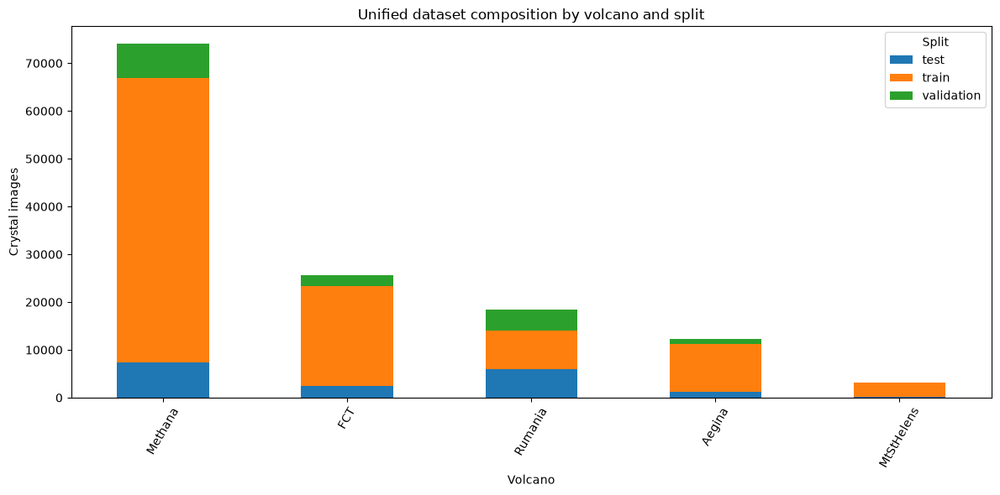

Saved: outputs/unified_dataset_eda_v1/figures/volcano_split_composition.png


In [6]:
fig, axis = plt.subplots(figsize=(12, 6))
volcano_split_table.drop(columns="total").plot(kind="bar", stacked=True, ax=axis)
axis.set_title("Unified dataset composition by volcano and split")
axis.set_xlabel("Volcano")
axis.set_ylabel("Crystal images")
axis.tick_params(axis="x", rotation=60)
axis.legend(title="Split")
fig.tight_layout()
path = FIGURE_ROOT / "volcano_split_composition.png"
fig.savefig(path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", path)

## 5. Resolve image paths safely

The resolver supports absolute paths, paths relative to the unified root and `image_root_map.json`. It raises `PermissionError` for test rows before attempting any filesystem image lookup.

In [7]:
ROOT_KEY_COLUMN_CANDIDATES = (
    "image_root_key", "root_key", "image_root", "source_root",
    "dataset_root", "dataset", "source_dataset", "source",
)


def locate_image_root_map() -> Path | None:
    expected = UNIFIED_ROOT / "metadata" / "image_root_map.json"
    if expected.is_file():
        return expected
    matches = list(UNIFIED_ROOT.glob("**/image_root_map.json"))
    return matches[0] if len(matches) == 1 else None


def flatten_root_map(payload: Any, prefix: str = "") -> dict[str, Path]:
    flattened: dict[str, Path] = {}
    if isinstance(payload, Mapping):
        for key, value in payload.items():
            child_prefix = f"{prefix}.{key}" if prefix else str(key)
            if isinstance(value, str):
                flattened[str(key)] = Path(value).expanduser()
                flattened[child_prefix] = Path(value).expanduser()
            else:
                flattened.update(flatten_root_map(value, child_prefix))
    return flattened


image_root_map_path = locate_image_root_map()
if image_root_map_path is None:
    IMAGE_ROOT_MAP: dict[str, Path] = {}
    print("No image_root_map.json found.")
else:
    IMAGE_ROOT_MAP = flatten_root_map(json.loads(image_root_map_path.read_text(encoding="utf-8")))
    print("Image root map:", image_root_map_path)
    print("Mapped roots:", len(IMAGE_ROOT_MAP))


def resolve_image_path(row: pd.Series, *, require_exists: bool = True) -> Path:
    split = str(row["_split"])
    if split not in IMAGE_ANALYSIS_SPLITS:
        raise PermissionError(f"Image access is disabled for split {split!r}.")

    reference = Path(str(row["_image_reference"])).expanduser()
    candidates: list[Path] = []

    if reference.is_absolute():
        candidates.append(reference)
    else:
        candidates.extend([UNIFIED_ROOT / reference, BENCHMARK_ROOT / reference])

        root_column = first_existing_column(row.to_frame().T, ROOT_KEY_COLUMN_CANDIDATES)
        if root_column is not None:
            root_key = str(row[root_column])
            if root_key in IMAGE_ROOT_MAP:
                candidates.append(IMAGE_ROOT_MAP[root_key] / reference)

        for root in IMAGE_ROOT_MAP.values():
            candidates.append(root / reference)

    unique_candidates: list[Path] = []
    seen: set[str] = set()
    for candidate in candidates:
        key = str(candidate)
        if key not in seen:
            unique_candidates.append(candidate)
            seen.add(key)

    if require_exists:
        for candidate in unique_candidates:
            if candidate.is_file():
                return candidate.resolve()
        raise FileNotFoundError(
            f"Could not resolve {reference!s} for split {split!r}; tried {len(unique_candidates)} paths."
        )

    if not unique_candidates:
        raise FileNotFoundError(f"No candidate paths generated for {reference!s}.")
    return unique_candidates[0]


permitted_manifest = manifest[manifest["_split"].isin(IMAGE_ANALYSIS_SPLITS)].copy()
print("Rows eligible for image analysis:", len(permitted_manifest))
print("Test rows excluded from image access:", int((manifest["_split"] == "test").sum()))

Image root map: /home/ars223/MSc-GEMS/IRP26/data/processed/plagnetplus/ssl_unified_v1/metadata/image_root_map.json
Mapped roots: 9
Rows eligible for image analysis: 116601
Test rows excluded from image access: 16988


## 6. Create a volcano-stratified image sample

In [8]:
def stratified_sample(
    frame: pd.DataFrame,
    *,
    group_column: str,
    maximum_rows: int | None,
    seed: int,
) -> pd.DataFrame:
    if maximum_rows is None or len(frame) <= maximum_rows:
        return frame.sample(frac=1.0, random_state=seed).reset_index(drop=True)

    counts = frame[group_column].value_counts(dropna=False)
    allocations = (counts / counts.sum() * maximum_rows).round().astype(int).clip(lower=1)

    while allocations.sum() > maximum_rows:
        reducible = allocations[allocations > 1]
        if reducible.empty:
            break
        allocations.loc[reducible.idxmax()] -= 1

    while allocations.sum() < maximum_rows:
        capacity = counts - allocations
        key = capacity.idxmax()
        if capacity.loc[key] <= 0:
            break
        allocations.loc[key] += 1

    groups: list[pd.DataFrame] = []
    for group, rows_to_take in allocations.items():
        group_rows = frame[frame[group_column] == group]
        groups.append(group_rows.sample(n=min(int(rows_to_take), len(group_rows)), random_state=seed))

    return pd.concat(groups, ignore_index=True).sample(frac=1.0, random_state=seed).reset_index(drop=True)


metric_sample = stratified_sample(
    permitted_manifest,
    group_column="_volcano",
    maximum_rows=MAX_IMAGES_FOR_METRICS,
    seed=RANDOM_SEED,
)

sample_counts = metric_sample["_volcano"].value_counts().rename("sampled_images").to_frame()
sample_counts = sample_counts.join(
    permitted_manifest["_volcano"].value_counts().rename("eligible_images")
)
sample_counts["sampling_fraction"] = sample_counts["sampled_images"] / sample_counts["eligible_images"]
display(sample_counts)
print("Metric-sample rows:", len(metric_sample))

,sampled_images,eligible_images,sampling_fraction
_volcano,,,
Methana,6868,66731,0.102921
FCT,2392,23241,0.102922
Rumania,1287,12509,0.102886
Aegina,1143,11103,0.102945
MtStHelens,310,3017,0.102751


Metric-sample rows: 12000


## 7. Compute image-level metrics

Metrics include dimensions, aspect ratio, intensity statistics, dynamic range, near-black/near-white fractions, entropy, edge density, a gradient-variance sharpness proxy, file size and exact SHA-256 hashes.

In [9]:
METRIC_CACHE = TABLE_ROOT / "image_metrics_sample.csv"


def shannon_entropy_uint8(array: np.ndarray) -> float:
    histogram = np.bincount(array.ravel(), minlength=256).astype(np.float64)
    probabilities = histogram / histogram.sum()
    probabilities = probabilities[probabilities > 0]
    return float(-(probabilities * np.log2(probabilities)).sum())


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def image_metrics(row: pd.Series) -> dict[str, Any]:
    result: dict[str, Any] = {
        "_split": row["_split"],
        "_volcano": row["_volcano"],
        "_sample_id": row["_sample_id"],
        "_image_reference": row["_image_reference"],
        "_manifest_row": row["_manifest_row"],
        "resolved_path": pd.NA,
        "read_ok": False,
        "error": pd.NA,
    }

    try:
        path = resolve_image_path(row)
        result["resolved_path"] = str(path)

        with Image.open(path) as image:
            image.load()
            grayscale = np.asarray(image.convert("L"), dtype=np.uint8)
            width, height = image.size

        float_image = grayscale.astype(np.float32)
        grad_y, grad_x = np.gradient(float_image)
        gradient_magnitude = np.hypot(grad_x, grad_y)
        p01, p99 = np.percentile(grayscale, [1, 99])

        result.update({
            "read_ok": True,
            "file_size_kb": path.stat().st_size / 1024,
            "width": int(width),
            "height": int(height),
            "pixel_area": int(width * height),
            "aspect_ratio": float(width / height) if height else np.nan,
            "intensity_mean": float(float_image.mean()),
            "intensity_std": float(float_image.std()),
            "intensity_p01": float(p01),
            "intensity_p99": float(p99),
            "dynamic_range_p01_p99": float(p99 - p01),
            "near_black_fraction": float((grayscale <= 5).mean()),
            "near_white_fraction": float((grayscale >= 250).mean()),
            "entropy_bits": shannon_entropy_uint8(grayscale),
            "edge_density": float((gradient_magnitude > np.percentile(gradient_magnitude, 75)).mean()),
            "gradient_variance": float(gradient_magnitude.var()),
            "sha256": sha256_file(path),
        })
    except (FileNotFoundError, PermissionError, UnidentifiedImageError, OSError, ValueError) as error:
        result["error"] = f"{type(error).__name__}: {error}"

    return result


if METRIC_CACHE.is_file():
    image_metric_table = pd.read_csv(METRIC_CACHE)
    print("Loaded cached metrics:", METRIC_CACHE)
else:
    records = [
        image_metrics(row)
        for _, row in tqdm(metric_sample.iterrows(), total=len(metric_sample), desc="Analysing images")
    ]
    image_metric_table = pd.DataFrame(records)
    image_metric_table.to_csv(METRIC_CACHE, index=False)
    print("Saved metric cache:", METRIC_CACHE)

print("Metric rows:", len(image_metric_table))
print("Readable images:", int(image_metric_table["read_ok"].astype(bool).sum()))
print("Unreadable/unresolved:", int((~image_metric_table["read_ok"].astype(bool)).sum()))
display(image_metric_table.head())

Analysing images: 100%|██████████| 12000/12000 [01:20<00:00, 149.71it/s]


Saved metric cache: outputs/unified_dataset_eda_v1/tables/image_metrics_sample.csv
Metric rows: 12000
Readable images: 12000
Unreadable/unresolved: 0


,_split,_volcano,_sample_id,_image_reference,_manifest_row,resolved_path,read_ok,error,file_size_kb,width,...,intensity_std,intensity_p01,intensity_p99,dynamic_range_p01_p99,near_black_fraction,near_white_fraction,entropy_bits,edge_density,gradient_variance,sha256
0,validation,Methana,11__Methana__M91-8791-71-1__M91-8791-71-1_0000...,images_masked/Methana/M91-8791-71-1/11__Methan...,4081,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...,True,<NA>,6.479492,162,...,15.658725,0.0,45.0,45.0,0.821140,0.0,1.336913,0.182327,12.225052,816144da5d7ac63a327281f2043fd63e0428b47818540a...
1,train,Methana,14__Methana__Met91-78-9-XII__Met91-78-9-XII_00...,images_masked/Methana/Met91-78-9-XII/14__Metha...,75766,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...,True,<NA>,25.125977,197,...,45.847431,0.0,134.0,134.0,0.576799,0.0,3.839299,0.246412,49.999458,076bcad0aacdf147e78b1ab3706e654a2ea83beb8c16a5...
2,train,Methana,13__Methana__Met91-77-8-XI__Met91-77-8-XI_0001...,images_masked/Methana/Met91-77-8-XI/13__Methan...,58653,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...,True,<NA>,17.158203,245,...,21.224977,0.0,60.0,60.0,0.779392,0.0,1.822538,0.222041,11.773416,457d2a39ab9dbdf2cff51bfc1147645a0e8c008a5f441c...
3,train,FCT,20__FCT__6861_FCT__6861_00007_00007__label_0017,images_masked/FCT/6861_FCT/20__FCT__6861_FCT__...,88772,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...,True,<NA>,3.336914,87,...,37.962788,0.0,106.0,106.0,0.736161,0.0,2.328202,0.244814,80.471397,5495c5cdeb97d19f3ac7bb7f744895a77e6813b3d50b6e...
4,train,Methana,13__Methana__Met91-77-8-XI__Met91-77-8-XI_0000...,images_masked/Methana/Met91-77-8-XI/13__Methan...,51272,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...,True,<NA>,2.677734,83,...,22.808084,0.0,61.0,61.0,0.748440,0.0,1.962475,0.237625,36.471367,6524a00bc1ec16f7aaa073279acf92063ce0425e8b3908...


In [10]:
failed_images = image_metric_table[~image_metric_table["read_ok"].astype(bool)].copy()
if failed_images.empty:
    print("All sampled images resolved and loaded successfully.")
else:
    display(failed_images["error"].value_counts(dropna=False).rename("images").to_frame().head(20))
    display(failed_images[["_split", "_volcano", "_sample_id", "_image_reference", "error"]].head(50))
    failed_images.to_csv(TABLE_ROOT / "failed_or_unresolved_images.csv", index=False)

All sampled images resolved and loaded successfully.


## 8. Image-metric summaries and distributions

In [11]:
readable_metrics = image_metric_table[image_metric_table["read_ok"].astype(bool)].copy()

NUMERIC_IMAGE_METRICS = [
    "file_size_kb", "width", "height", "pixel_area", "aspect_ratio",
    "intensity_mean", "intensity_std", "dynamic_range_p01_p99",
    "near_black_fraction", "near_white_fraction", "entropy_bits",
    "edge_density", "gradient_variance",
]

overall_metric_summary = readable_metrics[NUMERIC_IMAGE_METRICS].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T
volcano_metric_summary = readable_metrics.groupby("_volcano", observed=True)[NUMERIC_IMAGE_METRICS].agg(
    ["count", "median", "mean", "std"]
)

display(overall_metric_summary)
display(volcano_metric_summary)
overall_metric_summary.to_csv(TABLE_ROOT / "overall_image_metric_summary.csv")
volcano_metric_summary.to_csv(TABLE_ROOT / "volcano_image_metric_summary.csv")

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
file_size_kb,12000.0,28.423679,114.223269,0.707031,1.296865,1.780273,3.321289,6.133789,15.020264,106.517187,4.004357e+02,4.406431e+03
width,12000.0,189.124333,190.659439,43.000000,54.000000,63.000000,89.000000,130.000000,208.000000,530.050000,1.027010e+03,3.070000e+03
height,12000.0,189.124333,190.659439,43.000000,54.000000,63.000000,89.000000,130.000000,208.000000,530.050000,1.027010e+03,3.070000e+03
pixel_area,12000.0,72116.006000,257550.906070,1849.000000,2916.000000,3969.000000,7921.000000,16900.000000,43264.000000,280953.050000,1.054750e+06,9.424900e+06
aspect_ratio,12000.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000e+00,1.000000e+00
intensity_mean,12000.0,17.262079,10.802889,1.624853,3.955657,5.626792,9.772388,14.255110,21.442623,39.624764,5.353133e+01,1.226596e+02
intensity_std,12000.0,26.866402,12.526639,5.759813,11.553283,13.807080,18.197742,22.908440,31.839123,53.445528,6.626619e+01,1.145100e+02
dynamic_range_p01_p99,12000.0,77.329533,35.148588,21.000000,35.000000,41.000000,54.000000,66.000000,91.000000,150.000000,2.020000e+02,2.480000e+02
near_black_fraction,12000.0,0.719063,0.095426,0.349262,0.503097,0.560915,0.651092,0.719507,0.789468,0.874952,9.123052e-01,9.600045e-01
near_white_fraction,12000.0,0.000006,0.000142,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,8.615481e-03


file_size_kb                                   width         \
                  count     median       mean         std count median   
_volcano                                                                 
Aegina             1143   5.606445  31.858380  109.872192  1143  116.0   
FCT                2392   9.321777  48.963871  136.074948  2392  148.0   
Methana            6868   5.106445  14.121045   71.094505  6868  125.0   
MtStHelens          310  21.769531  67.765083  118.019611   310  240.0   
Rumania            1287  11.371094  54.046562  208.166338  1287  149.0   

                                   height         ... entropy_bits            \
                  mean         std  count median  ...         mean       std   
_volcano                                          ...                          
Aegina      188.281715  205.151709   1143  116.0  ...     2.058757  0.515132   
FCT         236.362876  243.412261   2392  148.0  ...     2.587679  0.638302   
Methana     154.659435  126.109595   6868  125.0  ...     2.080445  0.666706   
MtStHelens  332.383871  252.378609    310  240.0  ...     2.416958  0.557350   
Rumania     251.488733  268.470716   1287  149.0  ...     2.702995  0.689475   

           edge_density                               gradient_variance  \
                  count    median      mean       std             count   
_volcano                                                                  
Aegina             1143  0.239589  0.227226  0.030184              1143   
FCT                2392  0.242230  0.233827  0.023996              2392   
Methana            6868  0.234097  0.214471  0.042107              6868   
MtStHelens          310  0.236412  0.229551  0.021955               310   
Rumania            1287  0.243634  0.236103  0.020342              1287   

                                             
               median       mean        std  
_volcano                                     
Aegina      15.224552  17.368321  11.727887  
FCT         49.656261  60.855068  46.319937  
Methana     21.584062  25.963567  18.125406  
MtStHelens  19.261766  25.323289  22.763145  
Rumania     65.141991  74.739507  65.942838  

[5 rows x 52 columns]

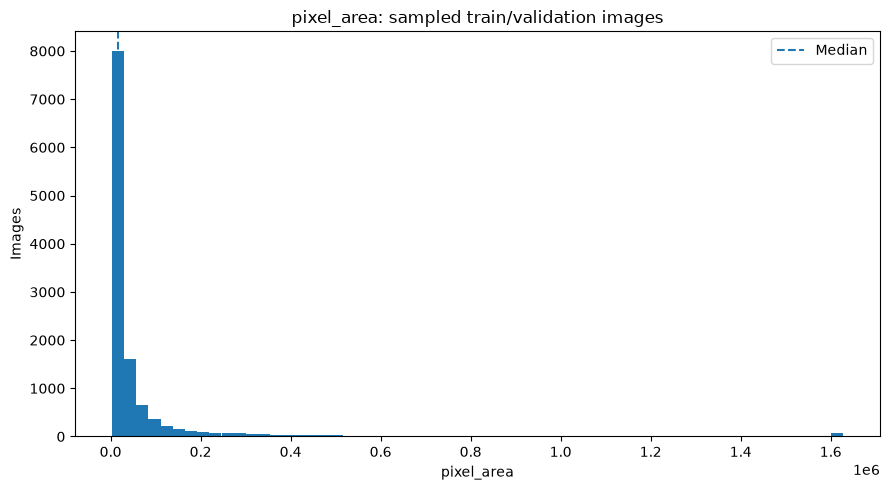

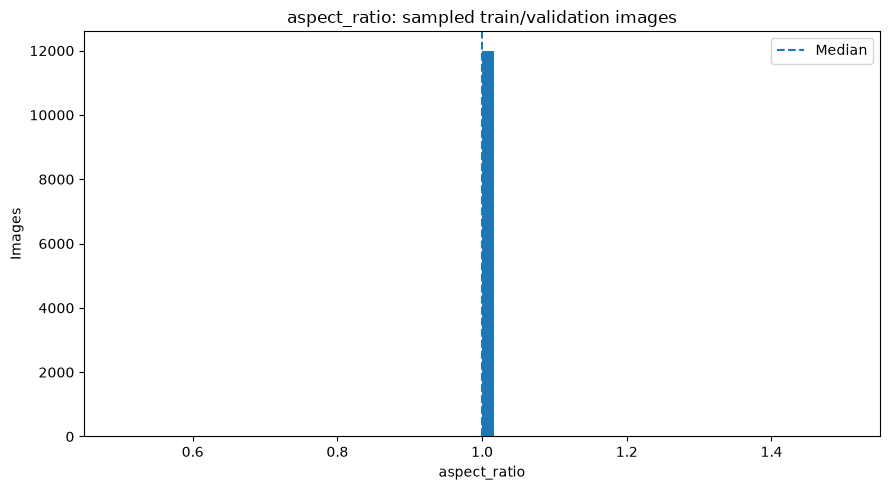

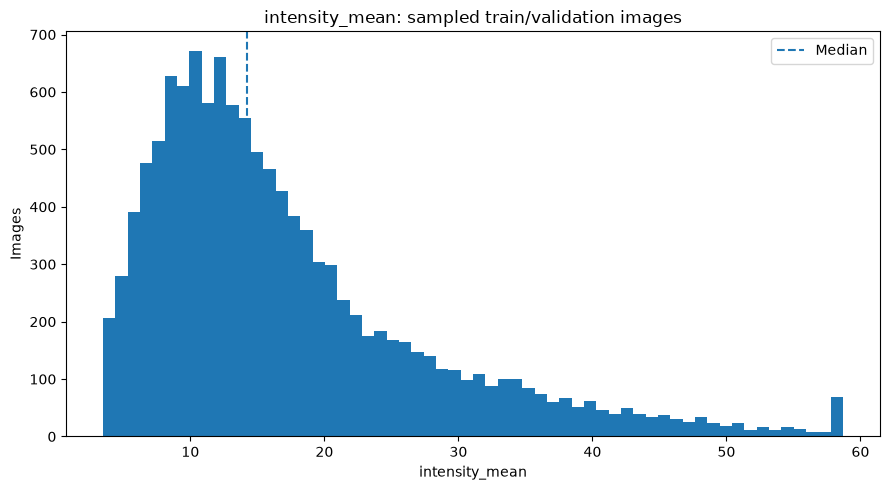

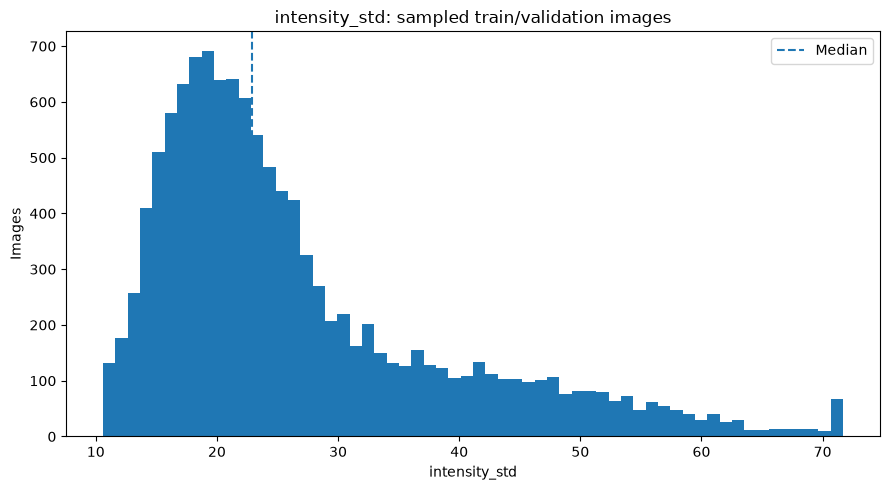

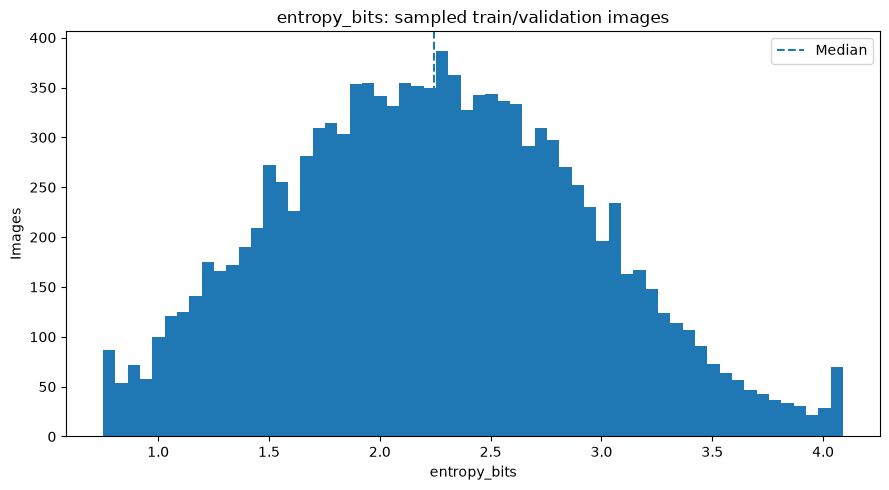

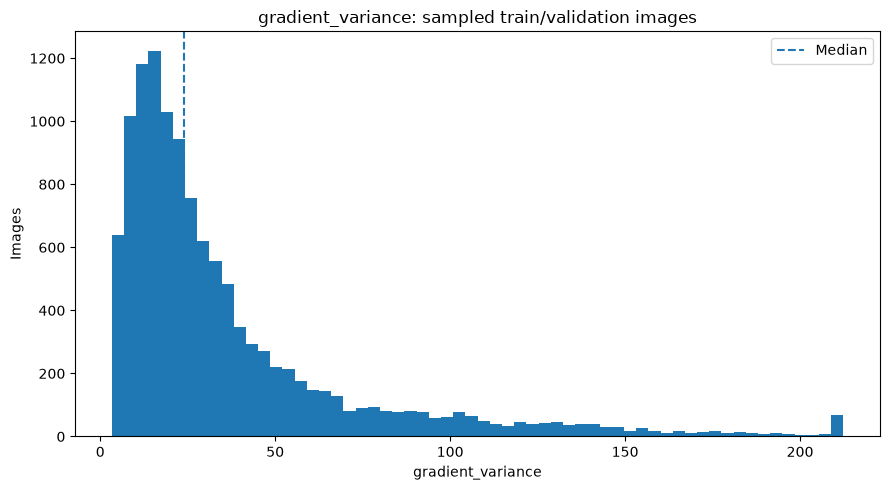

In [12]:
for metric in [
    "pixel_area", "aspect_ratio", "intensity_mean",
    "intensity_std", "entropy_bits", "gradient_variance",
]:
    values = readable_metrics[metric].replace([np.inf, -np.inf], np.nan).dropna()
    if values.empty:
        continue

    lower, upper = values.quantile([0.005, 0.995])
    fig, axis = plt.subplots(figsize=(9, 5))
    axis.hist(values.clip(lower, upper), bins=60)
    axis.axvline(values.median(), linestyle="--", label="Median")
    axis.set_title(f"{metric}: sampled train/validation images")
    axis.set_xlabel(metric)
    axis.set_ylabel("Images")
    axis.legend()
    fig.tight_layout()
    path = FIGURE_ROOT / f"distribution_{metric}.png"
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()

## 9. Robust outlier scoring

The notebook uses median/MAD robust z-scores globally and within each volcano. The combined score is the maximum absolute score over the selected metrics. Outlier scores are screening aids, not automatic exclusion rules.

In [13]:
OUTLIER_METRICS = [
    "file_size_kb", "pixel_area", "aspect_ratio", "intensity_mean",
    "intensity_std", "dynamic_range_p01_p99", "near_black_fraction",
    "near_white_fraction", "entropy_bits", "gradient_variance",
]


def robust_zscore(series: pd.Series) -> pd.Series:
    numeric = pd.to_numeric(series, errors="coerce")
    median = numeric.median()
    mad = (numeric - median).abs().median()
    if not np.isfinite(mad) or mad == 0:
        return pd.Series(np.zeros(len(numeric)), index=numeric.index, dtype=float)
    return (numeric - median) / (1.4826 * mad)


outlier_table = readable_metrics.copy()
global_columns: list[str] = []
volcano_columns: list[str] = []

for metric in OUTLIER_METRICS:
    global_column = f"global_rz__{metric}"
    volcano_column = f"volcano_rz__{metric}"
    outlier_table[global_column] = robust_zscore(outlier_table[metric])
    outlier_table[volcano_column] = outlier_table.groupby("_volcano", observed=True)[metric].transform(robust_zscore)
    global_columns.append(global_column)
    volcano_columns.append(volcano_column)

outlier_table["global_outlier_score"] = outlier_table[global_columns].abs().max(axis=1)
outlier_table["volcano_outlier_score"] = outlier_table[volcano_columns].abs().max(axis=1)
outlier_table["combined_outlier_score"] = outlier_table[
    ["global_outlier_score", "volcano_outlier_score"]
].max(axis=1)

outlier_table["dominant_global_metric"] = outlier_table[global_columns].abs().idxmax(axis=1).str.split("__").str[-1]
outlier_table["dominant_volcano_metric"] = outlier_table[volcano_columns].abs().idxmax(axis=1).str.split("__").str[-1]
outlier_table = outlier_table.sort_values("combined_outlier_score", ascending=False)
outlier_table.to_csv(TABLE_ROOT / "image_outlier_scores.csv", index=False)

display(outlier_table[[
    "_split", "_volcano", "_sample_id", "combined_outlier_score",
    "global_outlier_score", "volcano_outlier_score",
    "dominant_global_metric", "dominant_volcano_metric", "resolved_path",
]].head(30))

,_split,_volcano,_sample_id,combined_outlier_score,global_outlier_score,volcano_outlier_score,dominant_global_metric,dominant_volcano_metric,resolved_path
5882,train,Rumania,18__Rumania__1b__1b_00016_00000__label_0018,824.970307,824.970307,375.891038,file_size_kb,pixel_area,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...
1423,train,Methana,07__Methana__M83-7-1-_II__M83-7-1-(II)_00014_0...,802.661622,558.663815,802.661622,file_size_kb,file_size_kb,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...
4269,train,Methana,07__Methana__M83-7-1-_II__M83-7-1-(II)_00007_0...,675.793197,470.331158,675.793197,file_size_kb,file_size_kb,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...
6752,train,Rumania,18__Rumania__1b__1b_00012_00000__label_0003,658.500898,658.500898,286.968370,file_size_kb,file_size_kb,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...
1861,validation,Methana,11__Methana__M91-8791-71-1__M91-8791-71-1_0001...,571.727819,397.875215,571.727819,file_size_kb,file_size_kb,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...
7421,validation,FCT,03__FCT__83b__83b_00005_00001__label_0004,489.623168,489.623168,254.189753,file_size_kb,file_size_kb,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...
11818,train,Rumania,18__Rumania__1b__1b_00001_00004__label_0023,405.545442,405.545442,176.568193,file_size_kb,file_size_kb,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...
8284,validation,FCT,03__FCT__83b__83b_00005_00003__label_0003,393.526544,393.526544,204.239847,file_size_kb,file_size_kb,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...
9843,validation,Methana,11__Methana__M91-8791-71-1__M91-8791-71-1_0001...,369.725594,257.230343,369.725594,file_size_kb,file_size_kb,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...
1406,train,Rumania,18__Rumania__1b__1b_00004_00003__label_0016,350.305491,350.305491,152.459203,file_size_kb,file_size_kb,/home/ars223/MSc-GEMS/IRP26/data/processed/pla...


## 10. Gallery helpers

In [14]:
def load_display_image(path: str | Path) -> np.ndarray:
    with Image.open(path) as image:
        image.load()
        return np.asarray(image.convert("L"))


def show_gallery(
    frame: pd.DataFrame,
    *,
    title: str,
    subtitle_columns: Sequence[str] = (),
    maximum_images: int = 12,
    columns: int = 4,
    save_name: str | None = None,
) -> None:
    rows = frame.head(maximum_images).copy()
    if rows.empty:
        print(f"No images available for gallery: {title}")
        return

    columns = min(columns, len(rows))
    plot_rows = math.ceil(len(rows) / columns)
    fig, axes = plt.subplots(plot_rows, columns, figsize=(3.4 * columns, 3.5 * plot_rows), squeeze=False)

    for axis in axes.ravel():
        axis.axis("off")

    for axis, (_, row) in zip(axes.ravel(), rows.iterrows()):
        try:
            axis.imshow(load_display_image(row["resolved_path"]), cmap="gray")
            subtitle = [str(row[column]) for column in subtitle_columns if column in row.index and pd.notna(row[column])]
            axis.set_title("\n".join(subtitle), fontsize=9)
        except Exception as error:
            axis.text(0.5, 0.5, f"{type(error).__name__}\n{error}", ha="center", va="center", wrap=True)
        axis.axis("off")

    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    if save_name:
        path = FIGURE_ROOT / save_name
        fig.savefig(path, dpi=180, bbox_inches="tight")
        print("Saved:", path)
    plt.show()

## 11. Random and representative image sets from every volcano

Saved: outputs/unified_dataset_eda_v1/figures/volcano_aegina_random_gallery.png


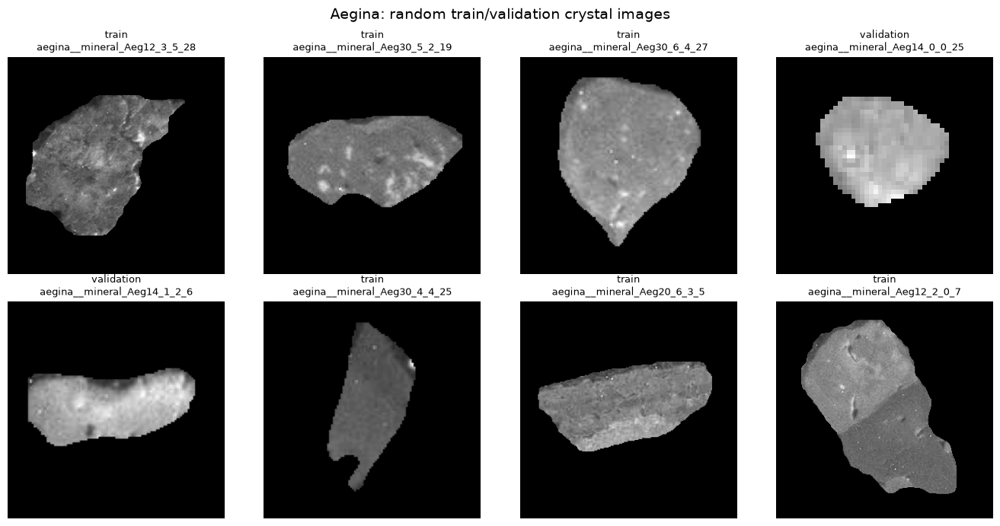

Saved: outputs/unified_dataset_eda_v1/figures/volcano_fct_random_gallery.png


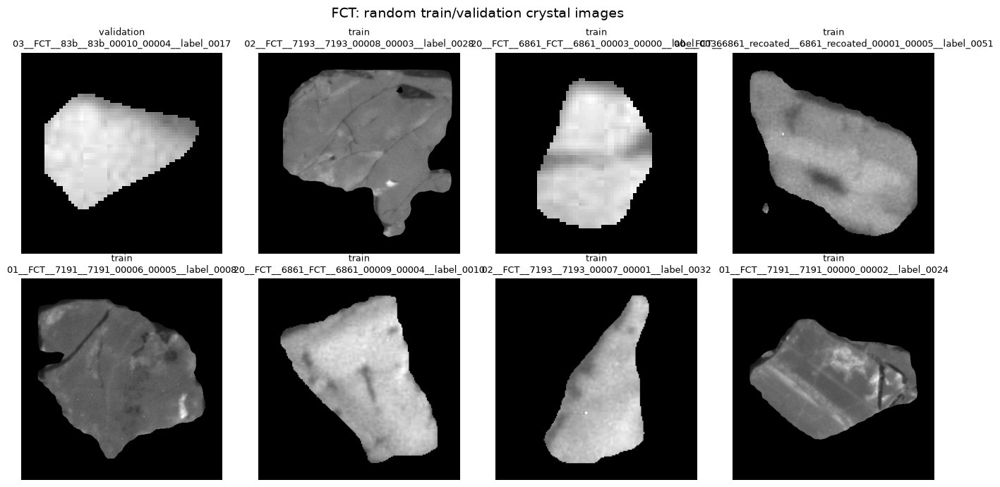

Saved: outputs/unified_dataset_eda_v1/figures/volcano_methana_random_gallery.png


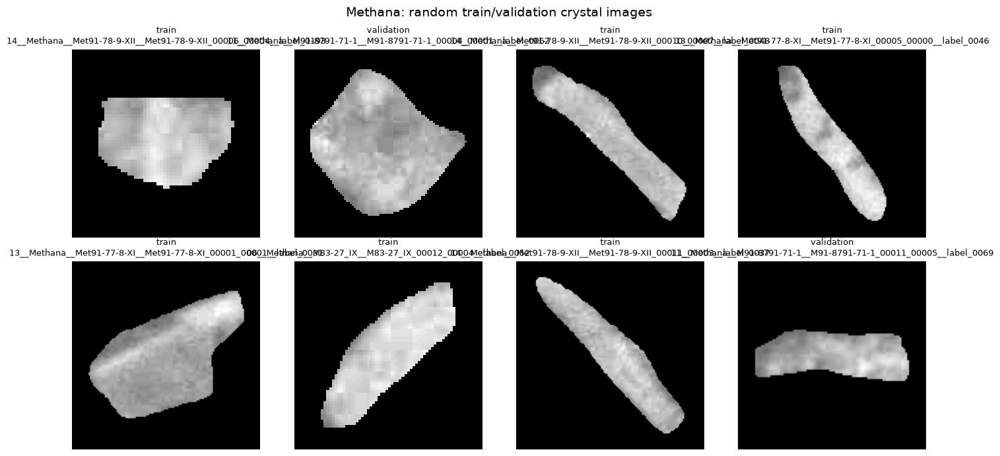

Saved: outputs/unified_dataset_eda_v1/figures/volcano_mtsthelens_random_gallery.png


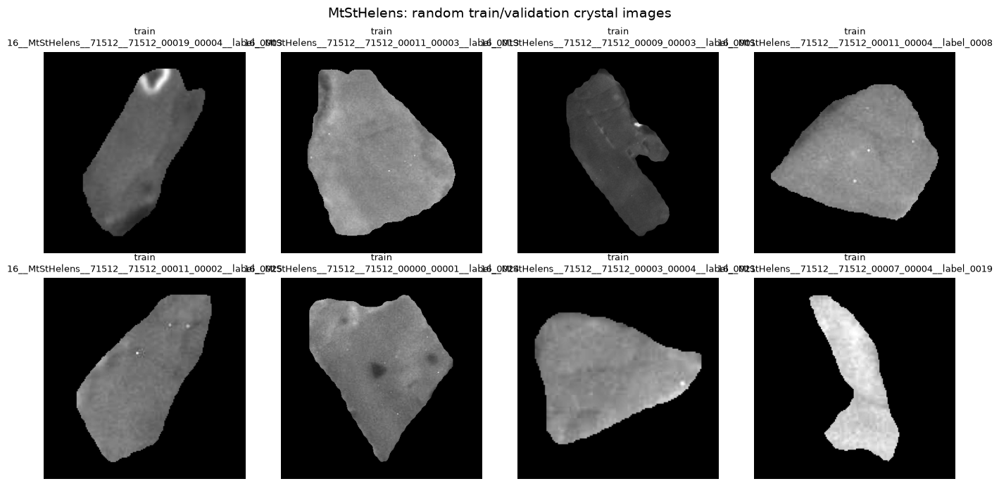

Saved: outputs/unified_dataset_eda_v1/figures/volcano_rumania_random_gallery.png


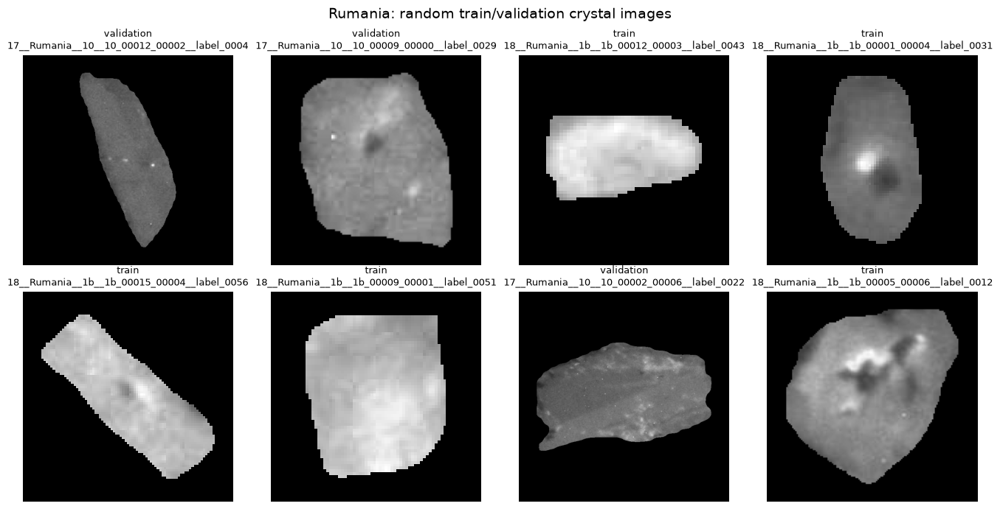

In [15]:
volcanoes = sorted(readable_metrics["_volcano"].dropna().astype(str).unique())

for volcano in volcanoes:
    rows = readable_metrics[readable_metrics["_volcano"] == volcano]
    count = min(IMAGES_PER_VOLCANO_GALLERY, len(rows))
    selected = rows.sample(n=count, random_state=RANDOM_SEED)
    safe_name = str(volcano).strip().lower().replace(" ", "_").replace("/", "_")
    show_gallery(
        selected,
        title=f"{volcano}: random train/validation crystal images",
        subtitle_columns=("_split", "_sample_id"),
        maximum_images=count,
        columns=4,
        save_name=f"volcano_{safe_name}_random_gallery.png",
    )

Saved: outputs/unified_dataset_eda_v1/figures/volcano_aegina_representative_gallery.png


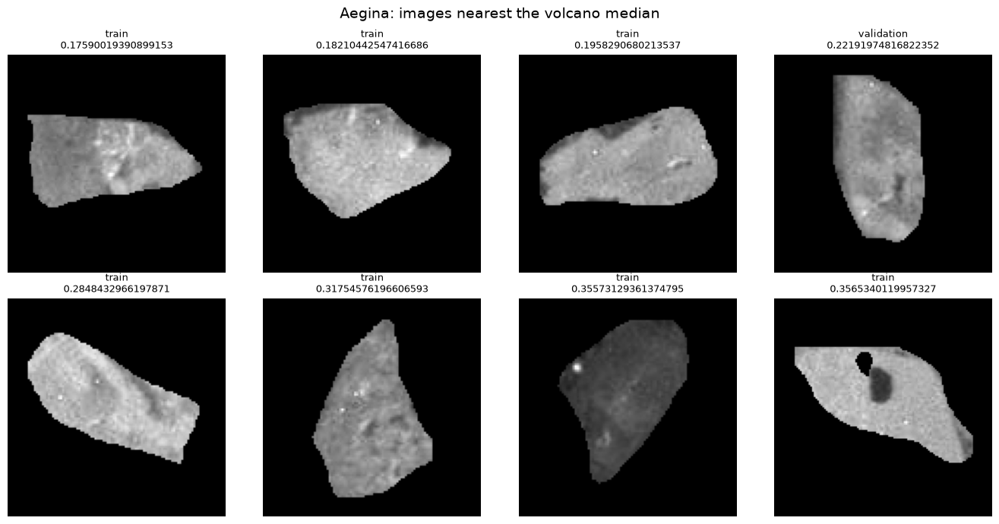

Saved: outputs/unified_dataset_eda_v1/figures/volcano_fct_representative_gallery.png


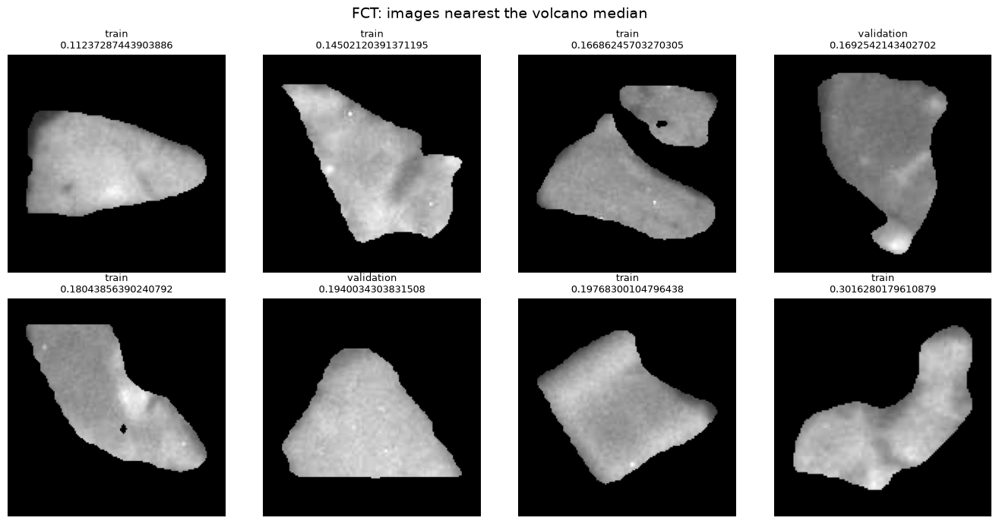

Saved: outputs/unified_dataset_eda_v1/figures/volcano_methana_representative_gallery.png


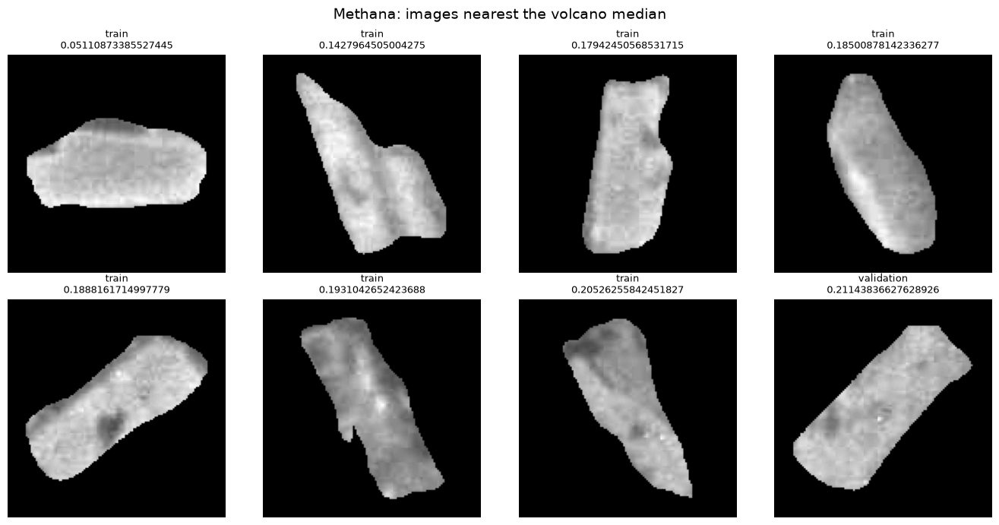

Saved: outputs/unified_dataset_eda_v1/figures/volcano_mtsthelens_representative_gallery.png


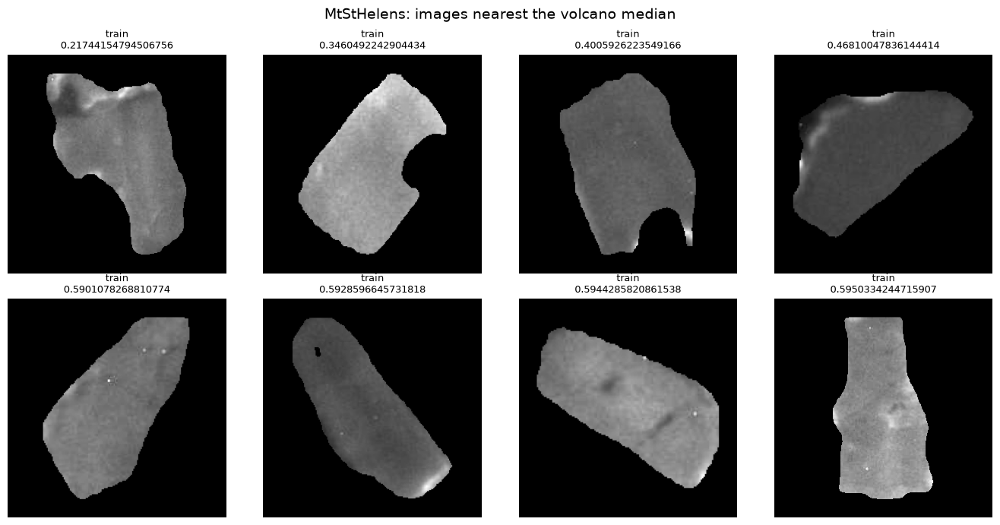

Saved: outputs/unified_dataset_eda_v1/figures/volcano_rumania_representative_gallery.png


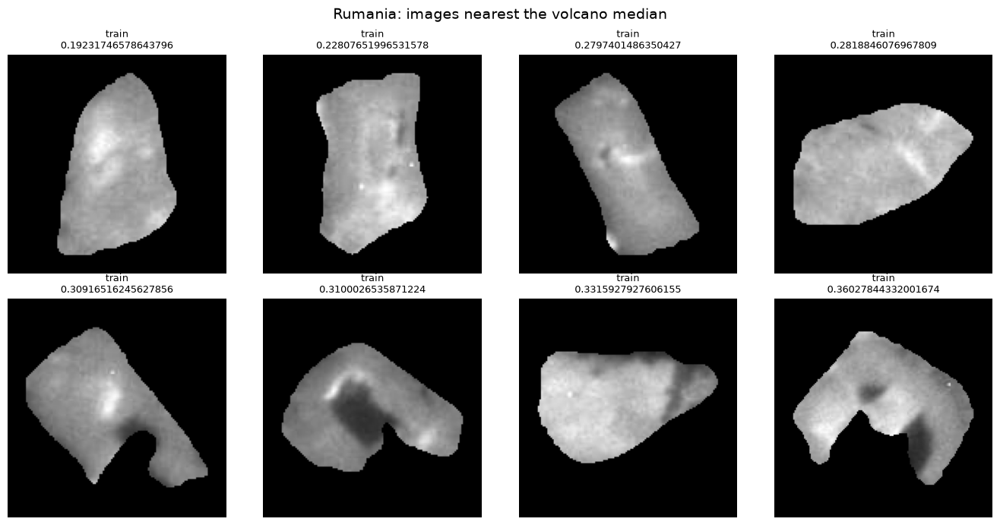

In [16]:
REPRESENTATIVE_METRICS = [
    "pixel_area", "aspect_ratio", "intensity_mean", "intensity_std", "entropy_bits"
]
representative_frames: list[pd.DataFrame] = []

for volcano, group in readable_metrics.groupby("_volcano", observed=True):
    group = group.copy()
    squared_distances = [robust_zscore(group[metric]).pow(2) for metric in REPRESENTATIVE_METRICS]
    group["median_distance"] = np.sqrt(sum(squared_distances))
    selected = group.nsmallest(min(IMAGES_PER_VOLCANO_GALLERY, len(group)), "median_distance")
    representative_frames.append(selected)
    safe_name = str(volcano).strip().lower().replace(" ", "_").replace("/", "_")
    show_gallery(
        selected,
        title=f"{volcano}: images nearest the volcano median",
        subtitle_columns=("_split", "median_distance"),
        maximum_images=len(selected),
        columns=4,
        save_name=f"volcano_{safe_name}_representative_gallery.png",
    )

representative_table = pd.concat(representative_frames, ignore_index=True)
representative_table.to_csv(TABLE_ROOT / "representative_images_by_volcano.csv", index=False)

## 12. Overall and volcano-specific outlier galleries

Saved: outputs/unified_dataset_eda_v1/figures/overall_outlier_gallery.png


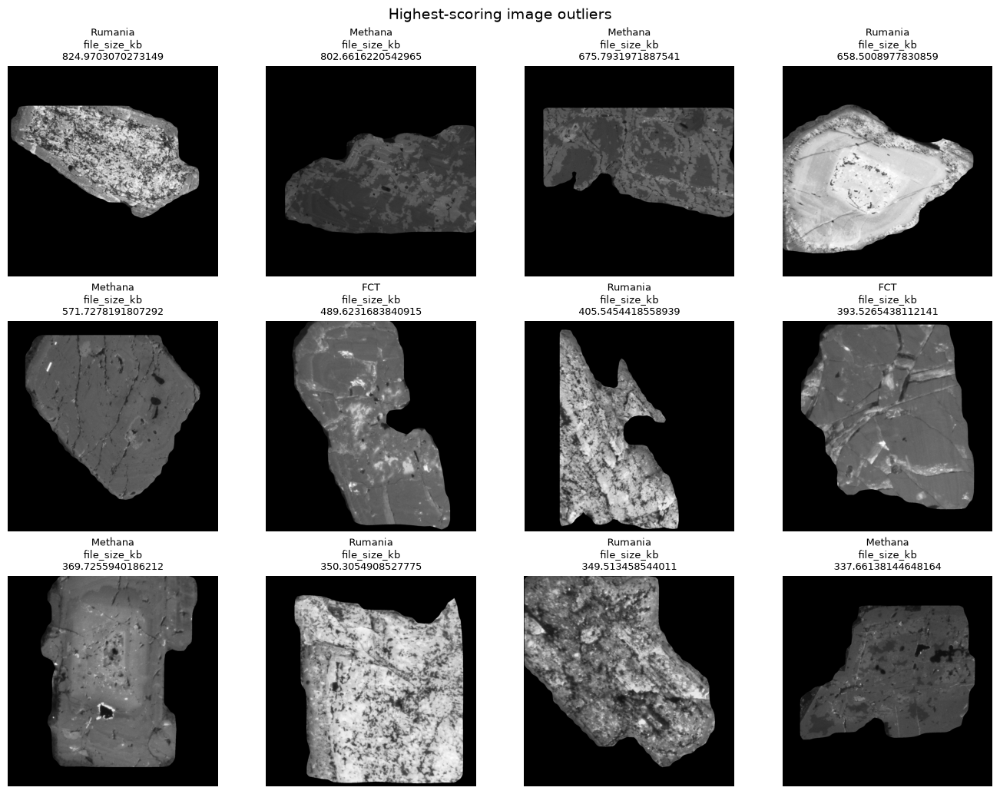

In [17]:
overall_outliers = outlier_table.nlargest(OUTLIERS_PER_GALLERY, "combined_outlier_score")
show_gallery(
    overall_outliers,
    title="Highest-scoring image outliers",
    subtitle_columns=("_volcano", "dominant_global_metric", "combined_outlier_score"),
    maximum_images=OUTLIERS_PER_GALLERY,
    columns=4,
    save_name="overall_outlier_gallery.png",
)

Saved: outputs/unified_dataset_eda_v1/figures/volcano_aegina_outlier_gallery.png


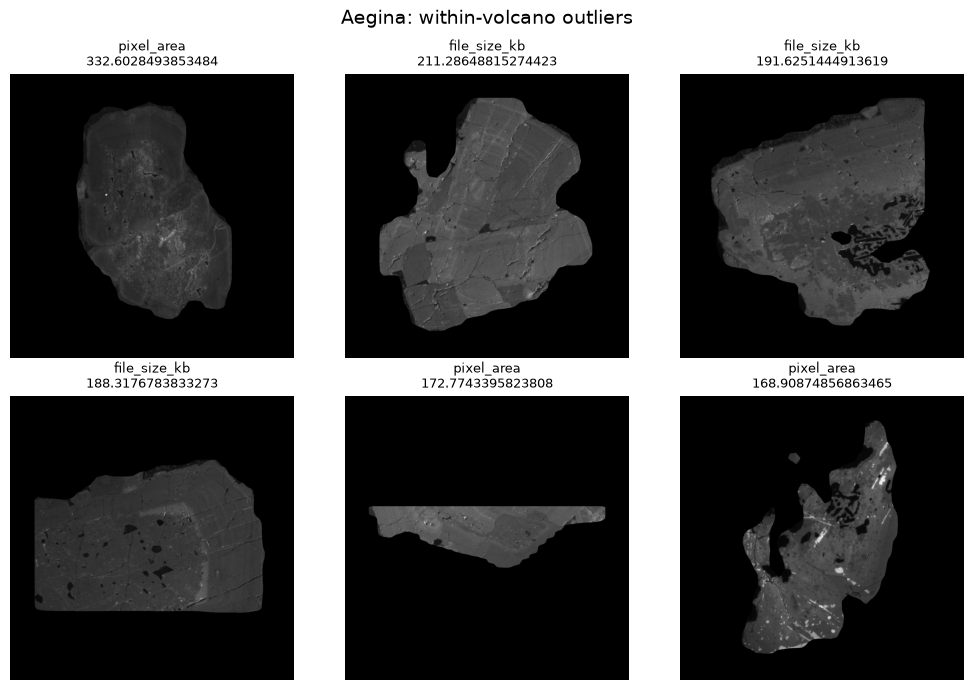

Saved: outputs/unified_dataset_eda_v1/figures/volcano_fct_outlier_gallery.png


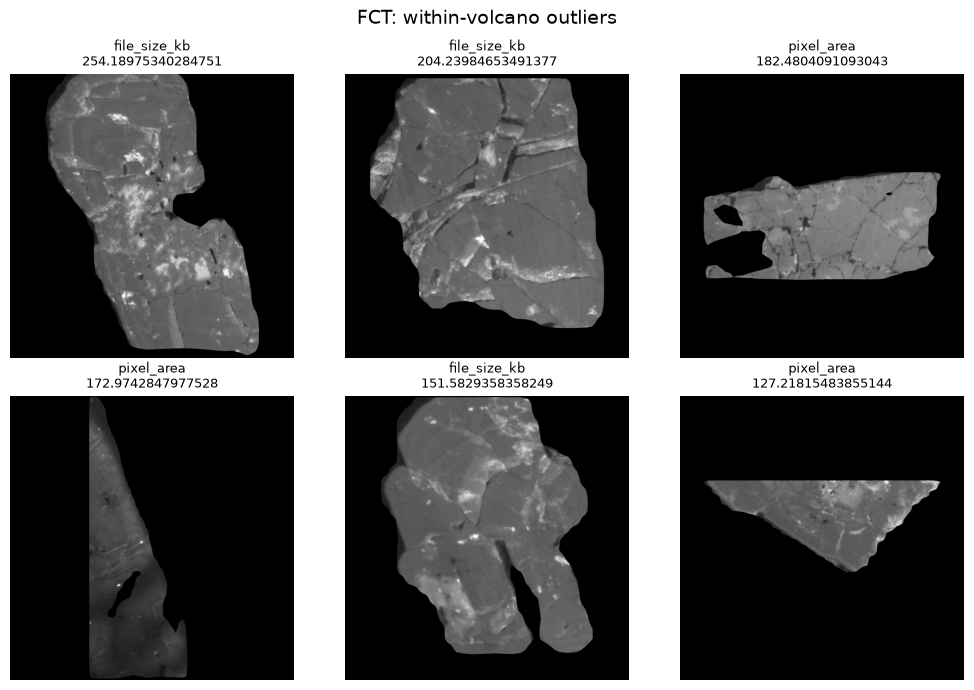

Saved: outputs/unified_dataset_eda_v1/figures/volcano_methana_outlier_gallery.png


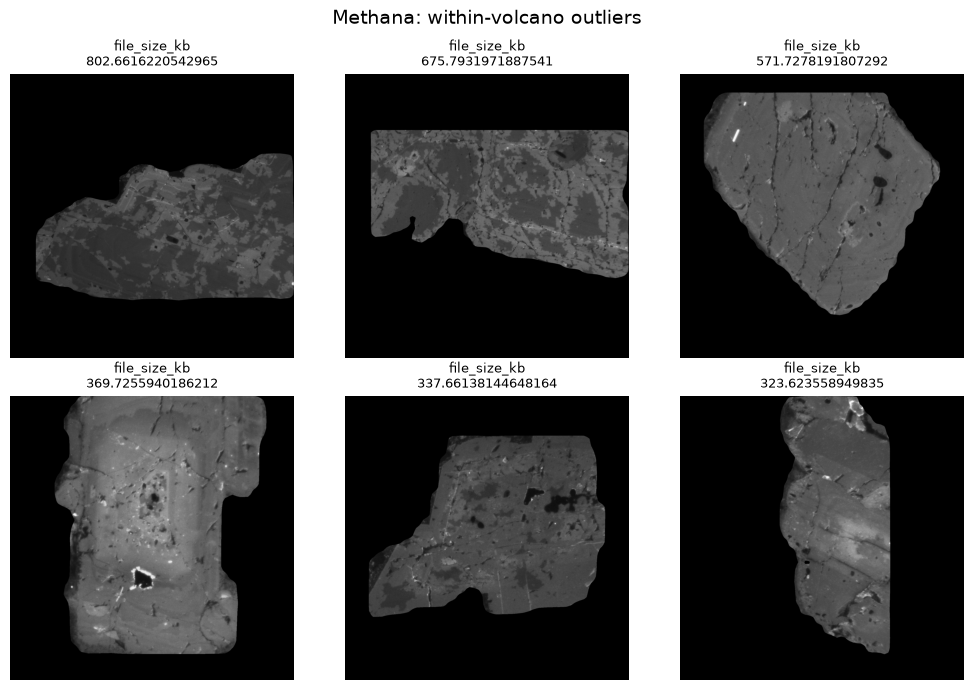

Saved: outputs/unified_dataset_eda_v1/figures/volcano_mtsthelens_outlier_gallery.png


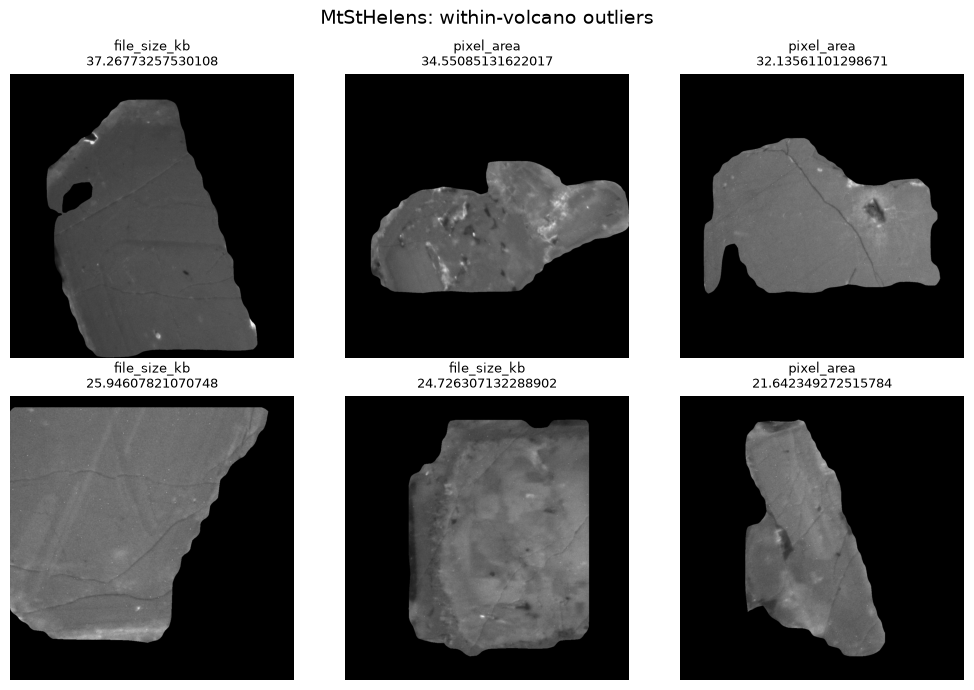

Saved: outputs/unified_dataset_eda_v1/figures/volcano_rumania_outlier_gallery.png


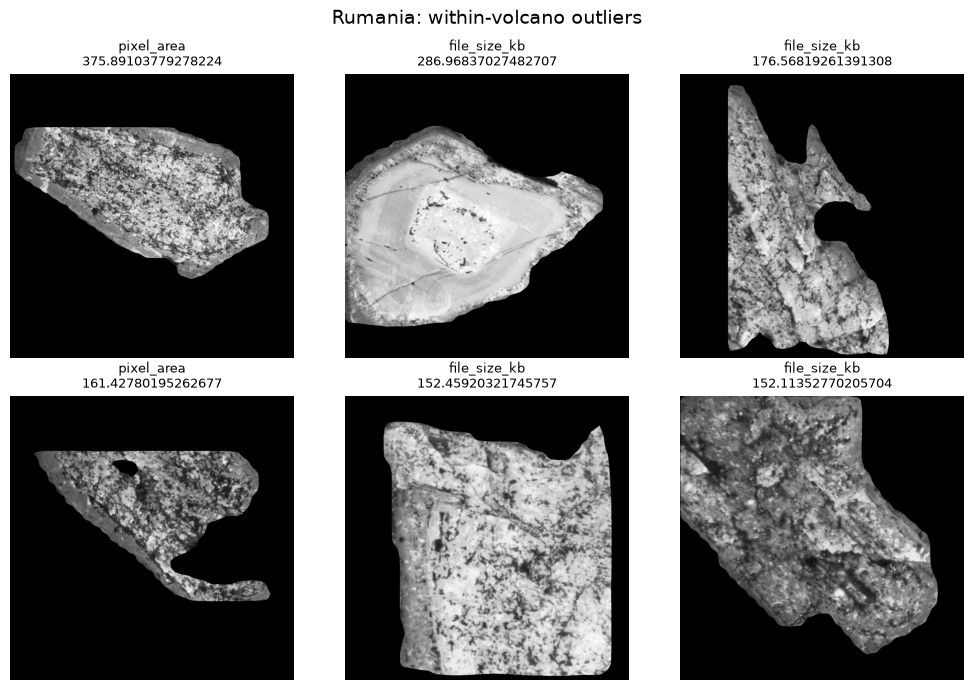

In [18]:
volcano_outlier_frames: list[pd.DataFrame] = []
for volcano, group in outlier_table.groupby("_volcano", observed=True):
    selected = group.nlargest(min(OUTLIERS_PER_VOLCANO, len(group)), "volcano_outlier_score")
    volcano_outlier_frames.append(selected)
    safe_name = str(volcano).strip().lower().replace(" ", "_").replace("/", "_")
    show_gallery(
        selected,
        title=f"{volcano}: within-volcano outliers",
        subtitle_columns=("dominant_volcano_metric", "volcano_outlier_score"),
        maximum_images=len(selected),
        columns=3,
        save_name=f"volcano_{safe_name}_outlier_gallery.png",
    )

volcano_outlier_table = pd.concat(volcano_outlier_frames, ignore_index=True)
volcano_outlier_table.to_csv(TABLE_ROOT / "top_outliers_by_volcano.csv", index=False)

## 13. Metric-specific outlier galleries

Saved: outputs/unified_dataset_eda_v1/figures/darkest_gallery.png


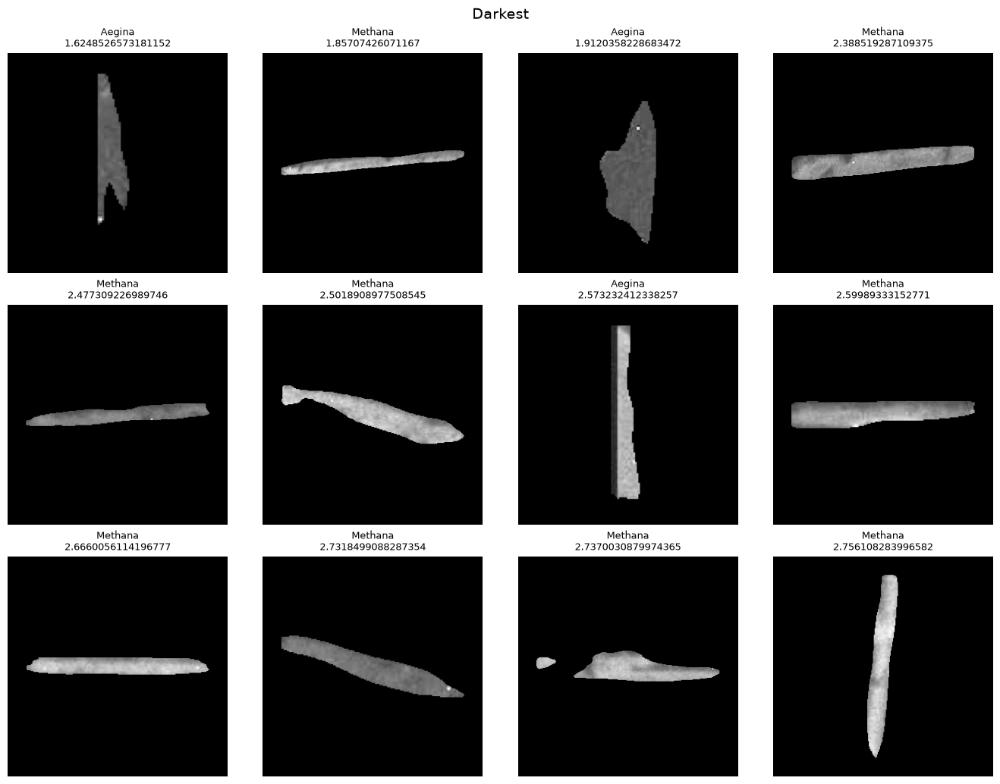

Saved: outputs/unified_dataset_eda_v1/figures/brightest_gallery.png


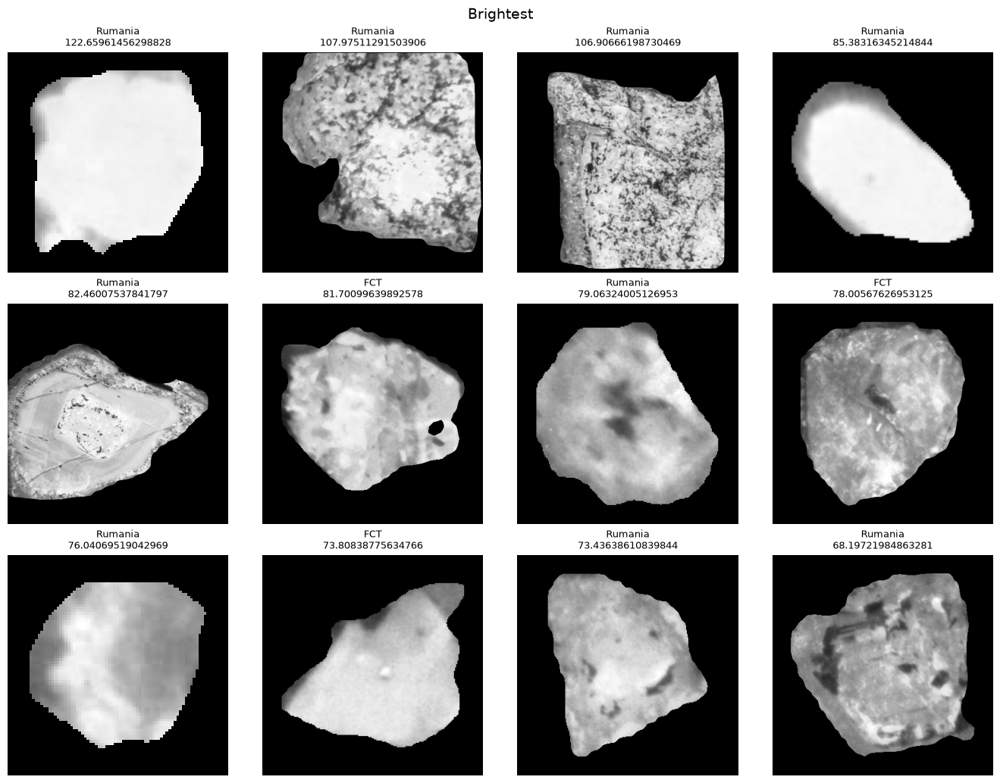

Saved: outputs/unified_dataset_eda_v1/figures/lowest_contrast_gallery.png


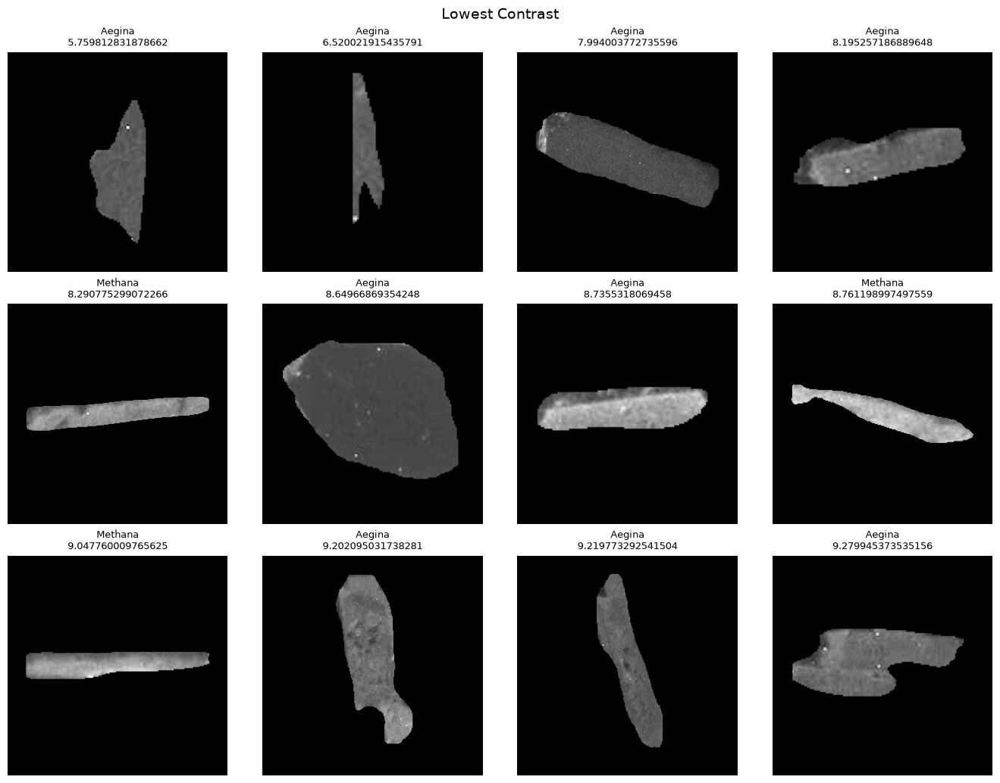

Saved: outputs/unified_dataset_eda_v1/figures/highest_contrast_gallery.png


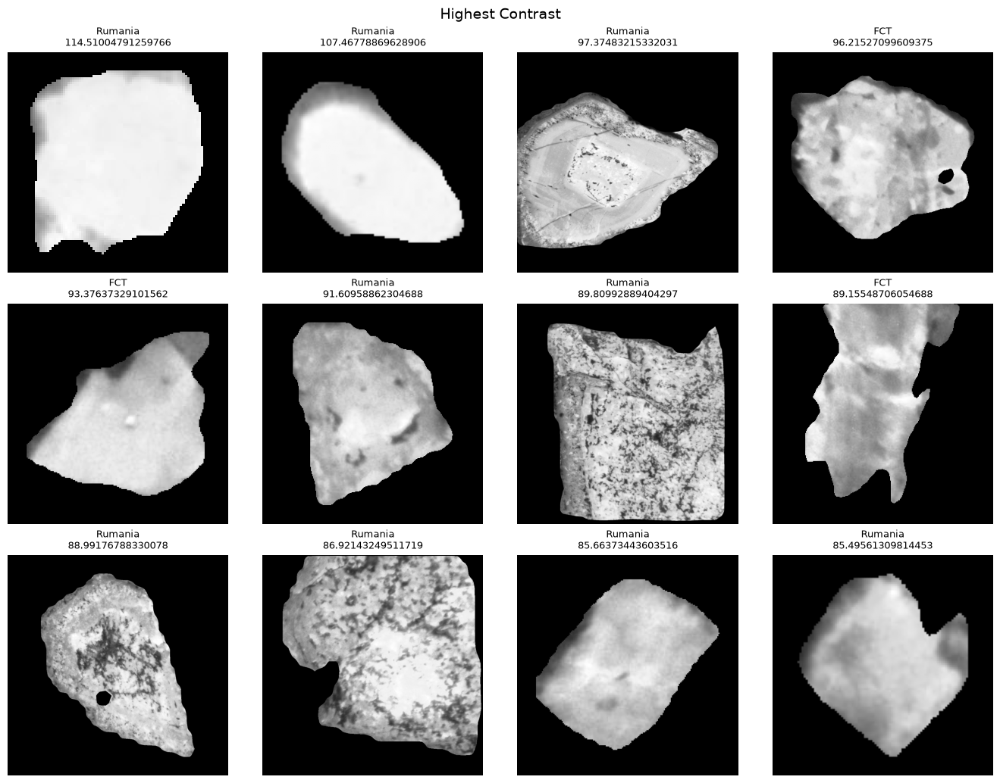

Saved: outputs/unified_dataset_eda_v1/figures/lowest_entropy_gallery.png


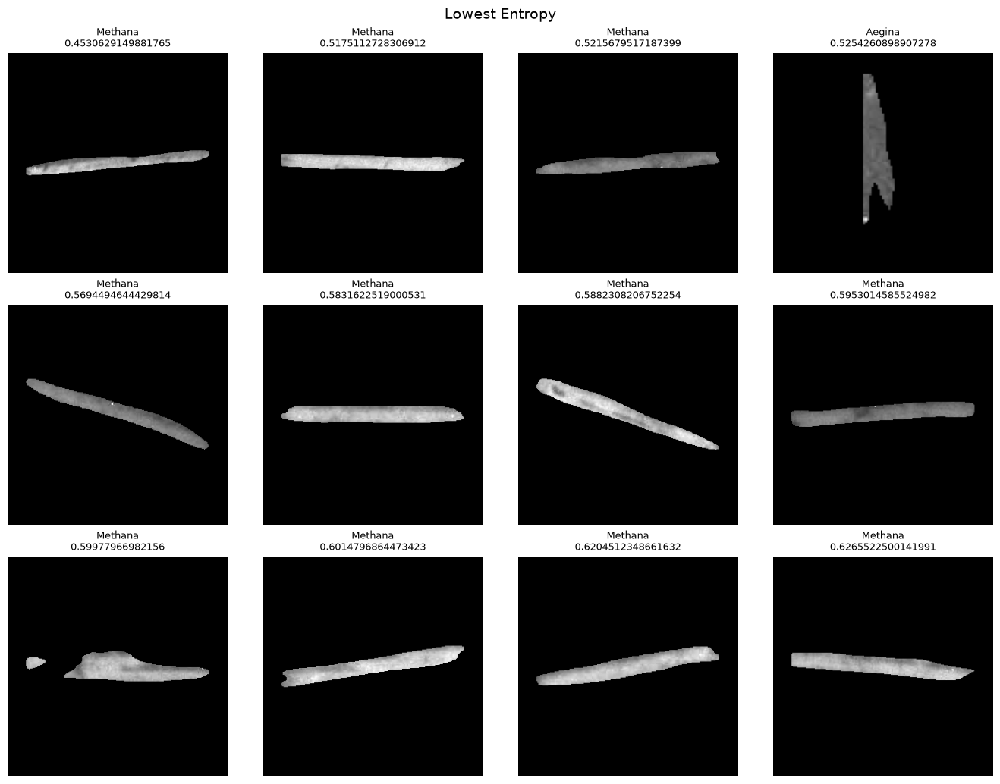

Saved: outputs/unified_dataset_eda_v1/figures/highest_entropy_gallery.png


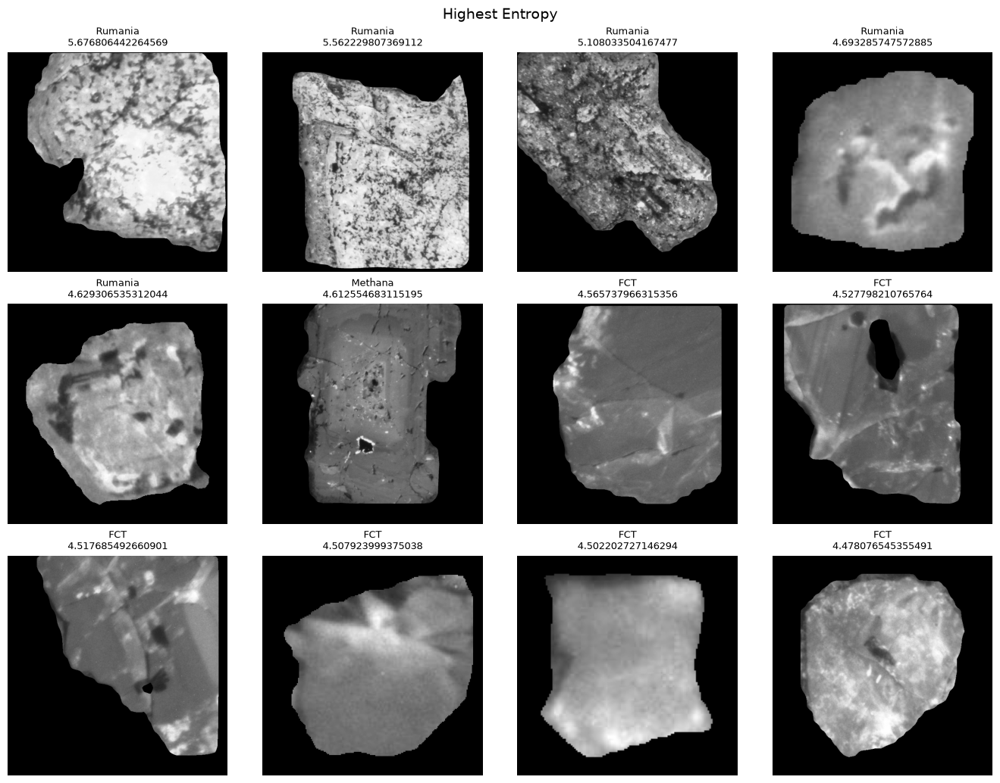

Saved: outputs/unified_dataset_eda_v1/figures/smallest_area_gallery.png


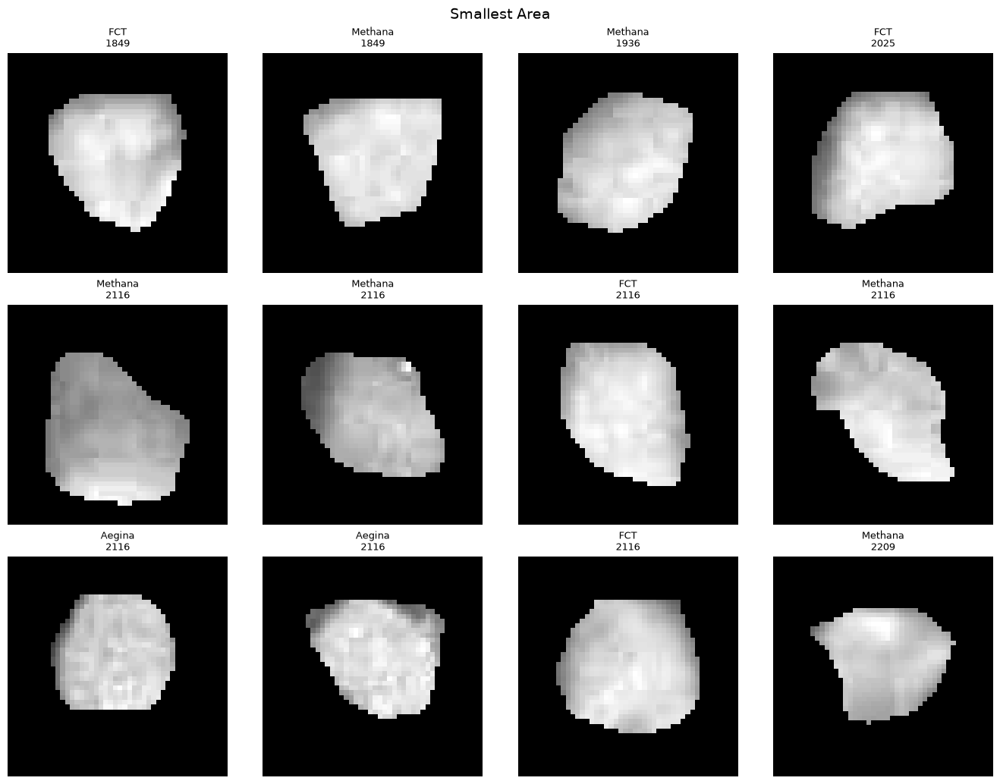

Saved: outputs/unified_dataset_eda_v1/figures/largest_area_gallery.png


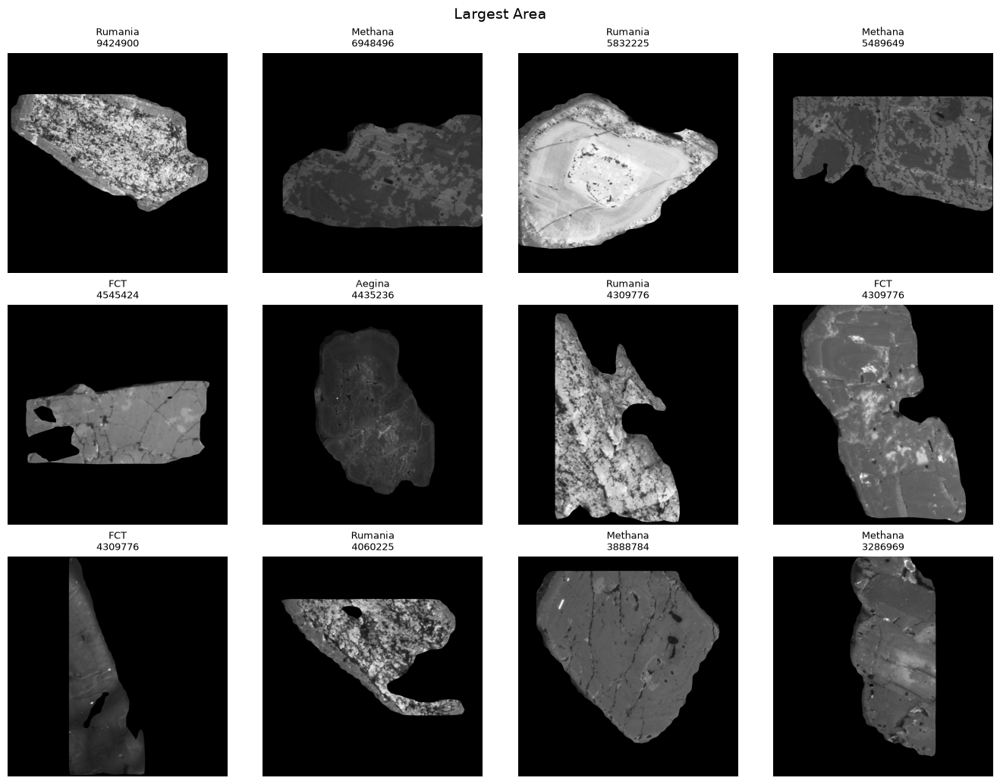

Saved: outputs/unified_dataset_eda_v1/figures/lowest_gradient_variance_gallery.png


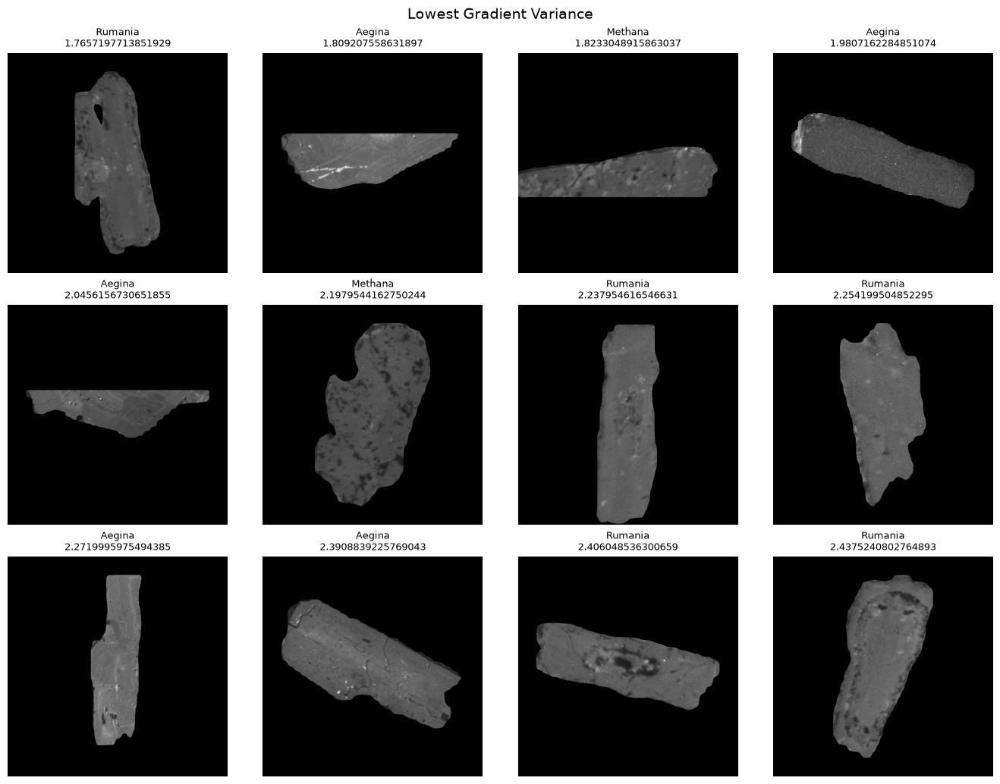

Saved: outputs/unified_dataset_eda_v1/figures/extreme_aspect_ratio_gallery.png


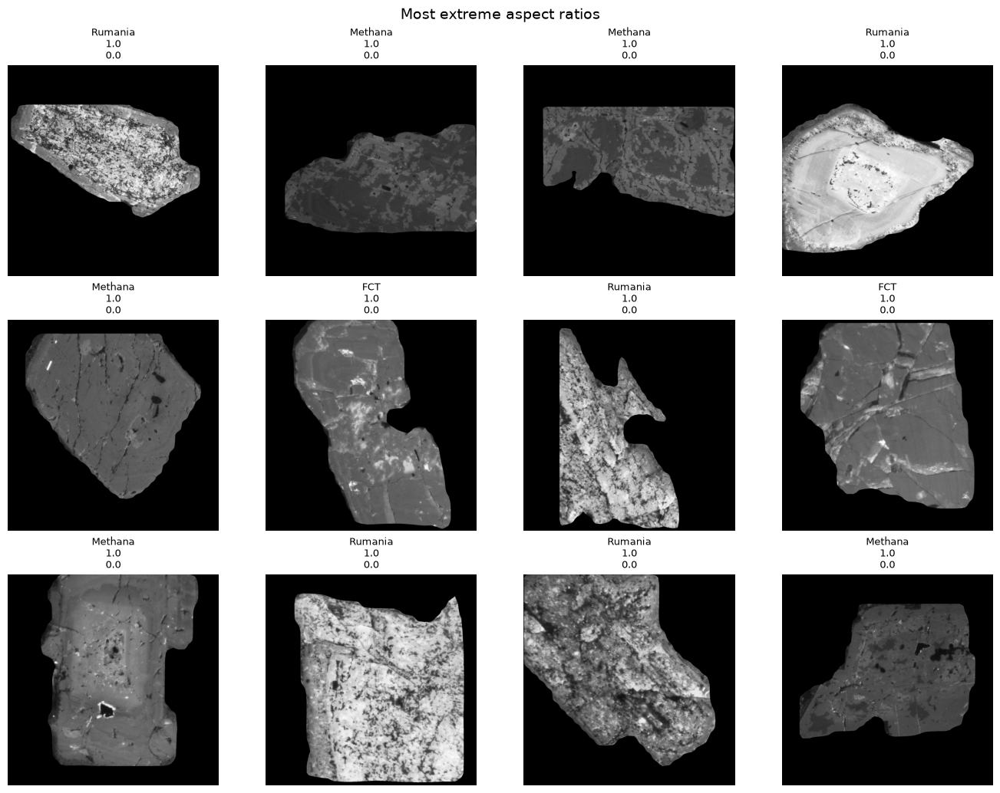

In [19]:
metric_gallery_specs = {
    "darkest": ("intensity_mean", True),
    "brightest": ("intensity_mean", False),
    "lowest_contrast": ("intensity_std", True),
    "highest_contrast": ("intensity_std", False),
    "lowest_entropy": ("entropy_bits", True),
    "highest_entropy": ("entropy_bits", False),
    "smallest_area": ("pixel_area", True),
    "largest_area": ("pixel_area", False),
    "lowest_gradient_variance": ("gradient_variance", True),
}

for gallery_name, (metric, ascending) in metric_gallery_specs.items():
    selected = outlier_table.sort_values(metric, ascending=ascending).head(OUTLIERS_PER_GALLERY)
    show_gallery(
        selected,
        title=gallery_name.replace("_", " ").title(),
        subtitle_columns=("_volcano", metric),
        maximum_images=OUTLIERS_PER_GALLERY,
        columns=4,
        save_name=f"{gallery_name}_gallery.png",
    )

extreme_aspect = outlier_table.assign(
    absolute_aspect_rz=outlier_table["global_rz__aspect_ratio"].abs()
).sort_values("absolute_aspect_rz", ascending=False).head(OUTLIERS_PER_GALLERY)
show_gallery(
    extreme_aspect,
    title="Most extreme aspect ratios",
    subtitle_columns=("_volcano", "aspect_ratio", "absolute_aspect_rz"),
    maximum_images=OUTLIERS_PER_GALLERY,
    columns=4,
    save_name="extreme_aspect_ratio_gallery.png",
)

## 14. Exact duplicate-image analysis

SHA-256 groups identify byte-identical files in the sampled training and validation images. Review especially any groups spanning splits or volcanoes.

In [20]:
duplicate_hash_rows = readable_metrics[
    readable_metrics.duplicated("sha256", keep=False)
].sort_values(["sha256", "_volcano", "_split"])

duplicate_hash_summary = (
    duplicate_hash_rows.groupby("sha256", observed=True)
    .agg(
        images=("_sample_id", "size"),
        volcanoes=("_volcano", "nunique"),
        splits=("_split", "nunique"),
        volcano_list=("_volcano", lambda values: " | ".join(sorted(set(map(str, values))))),
        split_list=("_split", lambda values: " | ".join(sorted(set(map(str, values))))),
    )
    .sort_values("images", ascending=False)
)

print("Images in exact-duplicate groups:", len(duplicate_hash_rows))
print("Exact-duplicate groups:", len(duplicate_hash_summary))
display(duplicate_hash_summary.head(30))
duplicate_hash_rows.to_csv(TABLE_ROOT / "exact_duplicate_image_rows.csv", index=False)
duplicate_hash_summary.to_csv(TABLE_ROOT / "exact_duplicate_image_groups.csv")

Images in exact-duplicate groups: 0
Exact-duplicate groups: 0


,images,volcanoes,splits,volcano_list,split_list
sha256,,,,,


## 15. Final exported summary

In [21]:
summary_payload = {
    "benchmark_id": BENCHMARK_ID,
    "unified_root": str(UNIFIED_ROOT),
    "manifest_rows": int(len(manifest)),
    "split_rows": {str(key): int(value) for key, value in manifest["_split"].value_counts().sort_index().items()},
    "volcanoes": int(manifest["_volcano"].nunique()),
    "image_analysis_splits": sorted(IMAGE_ANALYSIS_SPLITS),
    "test_images_opened": False,
    "eligible_image_rows": int(len(permitted_manifest)),
    "sampled_image_rows": int(len(metric_sample)),
    "readable_sampled_images": int(len(readable_metrics)),
    "failed_or_unresolved_images": int(len(failed_images)),
    "sampled_exact_duplicate_hash_groups": int(len(duplicate_hash_summary)),
    "sampled_images_in_duplicate_groups": int(len(duplicate_hash_rows)),
    "outputs": {
        "tables": str(TABLE_ROOT.resolve()),
        "figures": str(FIGURE_ROOT.resolve()),
        "image_metric_cache": str(METRIC_CACHE.resolve()),
    },
}

summary_path = OUTPUT_ROOT / "unified_dataset_eda_summary.json"
summary_path.write_text(json.dumps(summary_payload, indent=2, sort_keys=True) + "\n", encoding="utf-8")
print(json.dumps(summary_payload, indent=2, sort_keys=True))
print("Summary written to:", summary_path.resolve())
print("Test images opened: NO")

{
  "benchmark_id": "pooled_broad_p80_10_10_v1",
  "eligible_image_rows": 116601,
  "failed_or_unresolved_images": 0,
  "image_analysis_splits": [
    "train",
    "validation"
  ],
  "manifest_rows": 133589,
  "outputs": {
    "figures": "/home/ars223/MSc-GEMS/IRP26/plagnetplus-dev/notebooks/outputs/unified_dataset_eda_v1/figures",
    "image_metric_cache": "/home/ars223/MSc-GEMS/IRP26/plagnetplus-dev/notebooks/outputs/unified_dataset_eda_v1/tables/image_metrics_sample.csv",
    "tables": "/home/ars223/MSc-GEMS/IRP26/plagnetplus-dev/notebooks/outputs/unified_dataset_eda_v1/tables"
  },
  "readable_sampled_images": 12000,
  "sampled_exact_duplicate_hash_groups": 0,
  "sampled_image_rows": 12000,
  "sampled_images_in_duplicate_groups": 0,
  "split_rows": {
    "test": 16988,
    "train": 101682,
    "validation": 14919
  },
  "test_images_opened": false,
  "unified_root": "/home/ars223/MSc-GEMS/IRP26/data/processed/plagnetplus/ssl_unified_v1",
  "volcanoes": 5
}
Summary written to: /hom

## Questions to ask regarding each analysis stage:

1. **Volcano imbalance:** Are some volcanoes strongly over-represented?
2. **Split consistency:** Does each volcano appear in every intended split, with plausible proportions?
3. **Geometry:** Are dimensions and aspect ratios consistent with preprocessing expectations?
4. **Acquisition effects:** Do volcanoes differ systematically in brightness, contrast or entropy?
5. **Low-information crops:** Do low entropy, low contrast or low gradient variance reveal blank, saturated or blurred images?
6. **Outliers:** Are high scores genuine textures, segmentation failures, border crops or corrupt files?
7. **Duplicate leakage:** Do exact duplicate groups cross training and validation splits?
8. **Representative galleries:** Do median-like examples look scientifically representative for every volcano?
9. **Volcano-specific anomalies:** Are unusual images concentrated in one source or acquisition batch?
10. **Test protection:** Confirm the final summary contains `"test_images_opened": false`.

Do not remove images automatically from outlier scores. Any exclusions should be visually reviewed and recorded in a separate versioned quality-control table.